# §9 Robustness and Credibility

§7 reached its verdicts on one set of folds, one label, one imputation rule and one C. This section asks how much of
that is **procedure** and how much is **data**: negative and positive controls (§9.2), seed, specification, cluster
and missing-data stability of the headline contrast (§9.3–§9.7), external validity against NCHS Data Brief 516
(§9.8), a leak hunt for disguised labels among the admissible features (§9.9), the internal hold-out check (§9.11,
evaluated once after the `exp-freeze` tag) and the post-audit corrections of an external review (§9.12, post-lock).
Everything before §9.11 uses the training part only (4,584 rows). The headline contrast is
ΔAUC(S − M1), H2b(a) (locked rule: *supported* = equivalence within ±0.01; §7 verdict *inconclusive*).

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as sv, robustness as RB
from src.robustness import Spec

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))

warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("PYTHONWARNINGS", "ignore")
OUT = C.RESULTS_DIR / "S9"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(16, max(1, (os.cpu_count() or 2) - 2))
T_START = time.time()
# FAST mode (the re-run setting, <= ~5 min for the whole notebook) shrinks three extension-level loops; FINAL is unchanged:
# coefficient bootstrap of the noise check 500 -> 30 (config FAST value 100), robustness seeds 10 -> 5, specification
# curve 60 -> 30 specifications (C in {0.1, 10} instead of four values; C is the factor that matters least, see 5).
B_COEF9 = C.N_BOOT_COEF if C.IS_FINAL else 30
N_SEEDS = C.N_ROBUSTNESS_SEEDS if C.IS_FINAL else 5
C_CURVE = RB.C_GRID if C.IS_FINAL else (0.1, 10.0)
S9 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm": C.N_PERM,
      "n_boot_coef": B_COEF9, "n_seeds": N_SEEDS, "n_curve": 15 * len(C_CURVE)}
OI = C.OKABE_ITO
S7m = R.load_section("S7")
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, permutations = {C.N_PERM}, coefficient B = {B_COEF9}, "
      f"{N_SEEDS} robustness seeds, {S9['n_curve']}-specification curve, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, permutations = 100, coefficient B = 500, 10 robustness seeds, 60-specification curve, 16 workers


## 1 Reference comparison
**Why.** Every robustness check varies one thing against a fixed reference, so the reference must be
exactly the §7 run: same training part, same stored folds, frozen C0, same comparison engine
(`robustness.compare` mirrors the §7 engine: Nadeau–Bengio corrected t and paired bootstrap, wider interval on
E-ALL; bootstrap only on E-SCREEN).

In [2]:
# Load the context of §7 (training part only, stored folds, frozen C0) and reproduce the headline contrast S -
# M1 once as the reference for every check below. Reads results/splits and the stored results; asserts that
# folds, hold-out hash and (FINAL mode) the stored estimate are unchanged.
ctx = RB.load_context()
RUNS = {}                                              # cache: (Spec, folds hash) -> OOF frame
# Only the hash of the hold-out SEQNs is read here; the hold-out rows themselves stay unread until §9.11.
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
# A FINAL run must use exactly the folds stored by §7. FAST runs use fewer CV repeats, so the check is skipped
# there.
assert ctx.folds.hash == S7m["splits"]["folds_hash"] or not C.IS_FINAL, "FINAL run must use the S7 folds"
# The hold-out recorded on disk must be the one that was logged when the training part was split.
assert hold["sha256_test_seqn"] == S7m["splits"]["holdout_sha256"]
print(f"training part {ctx.n:,} rows, {ctx.y.sum()} L_comb positives; E-SCREEN {ctx.esc.sum():,} rows, "
      f"{ctx.y_esc[ctx.esc].sum()} positives; folds {len(ctx.folds)} ({ctx.folds.path.name}, hash {ctx.folds.hash[:12]}...)")
print(f"frozen C0 = {ctx.C0}; hold-out {len(ctx.test_idx):,} rows (SHA-256 {hold['sha256_test_seqn'][:16]}...) not read here")

def pair(spec_a, spec_b, folds=None, *, tag, label="L_comb", rows=None, use_t=True, w=None):
    """Run two specs (cached) and compare A - B on E-ALL (label) and E-SCREEN; returns two rows."""
    folds = ctx.folds if folds is None else folds
    oof = RB.run_many(ctx, {"a": spec_a, "b": spec_b}, folds, n_jobs=N_JOBS, cache=RUNS)
    f, mask = RB.spec_folds(ctx, spec_a, folds)
    _, mb = RB.spec_folds(ctx, spec_b, folds)
    # A paired comparison is only valid on identical rows (row subsets such as complete cases apply to both
    # specs).
    assert (mask == mb).all(), "paired specs must use the same rows"
    lab = ctx.labels[label].to_numpy()[mask].astype(int)
    # E-SCREEN = people without a reported diagnosis, scored against the HbA1c-only label (§1).
    esc, y_esc = ctx.esc[mask], ctx.y_esc[mask]
    ww = None if w is None else w[mask]
    out = []
    # The corrected t interval is used on E-ALL only; E-SCREEN uses the paired bootstrap alone, as in §7. The
    # bootstrap seed depends on (tag, population): reproducible, but different for every comparison.
    for pop, yy, m, t in (("E-ALL", lab, None, use_t), ("E-SCREEN", y_esc, esc, False)):
        r = RB.compare(oof["a"], oof["b"], yy, f, mask=m, w=ww, use_t=t, seed_=RB.seed(tag, pop))
        out.append(dict(tag=tag, pop=pop, **r))
    return out

# Reference contrast: delta = AUC(S) - AUC(M1) with the settings of §7.
ref = pair(Spec("S"), Spec("M1"), tag="reference")
ref_df = pd.DataFrame(ref)
show(ref_df[["pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b"]], 4)
# The stored scoreboard row of the same contrast (H2b(a), E-ALL, Tier 1) from §7.
s7_ref = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "H2b" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
# 5e-5 = agreement to the fourth decimal, the precision at which the stored value is quoted.
if C.IS_FINAL:   # identical folds, model and engine -> identical numbers
    assert abs(ref[0]["est"] - s7_ref["est"]) < 5e-5 and abs(ref[0]["hi"] - s7_ref["hi"]) < 5e-5, (ref[0]["est"], s7_ref)
print(f"S7 stored (FINAL): {s7_ref['est']:+.4f} [{s7_ref['lo']:+.4f}, {s7_ref['hi']:+.4f}] -> {s7_ref['verdict']}")
# Keep the reference per population; the tables and figures below compare against it.
S9["reference"] = {r["pop"]: {k: r[k] for k in ("auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b")} for r in ref}

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives; folds 25 (folds_FINAL.npz, hash 0d20f8f706eb...)
frozen C0 = 0.1; hold-out 1,146 rows (SHA-256 616fd0590bec7b92...) not read here


pop,auc_a,auc_b,est,lo,hi,interval,mdd,h2b
E-ALL,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,0.0112,inconclusive
E-SCREEN,0.7807,0.7723,0.0085,-0.0081,0.0236,bootstrap,0.0228,inconclusive


S7 stored (FINAL): +0.0079 [+0.0000, +0.0158] -> inconclusive


**So what.** In FINAL mode the reference reproduces §7 to the fourth decimal (asserted): S is ahead of M1 by about
+0.008 AUC on E-ALL with an interval from about 0 to +0.016, so H2b(a) is *inconclusive*. The question for every check
below is whether this verdict – not the point estimate – survives.

## 2 Negative and positive controls
### 2.1 Label permutation
**Why.** A model refitted on *permuted* labels must score 0.5 if the procedure leaks nothing (Ojala & Garriga 2010);
acceptance: null mean in [0.495, 0.505]. It cannot detect feature leakage – that is §9.9's job.

arm,observed,null_mean,null_sd,null_min,null_max,p_value,n_perm,in_band
M1,0.8274,0.5015,0.0127,0.4678,0.5352,0.0099,100,True
S,0.8351,0.5014,0.0130,0.4698,0.5287,0.0099,100,True


5050 fits in 485 s


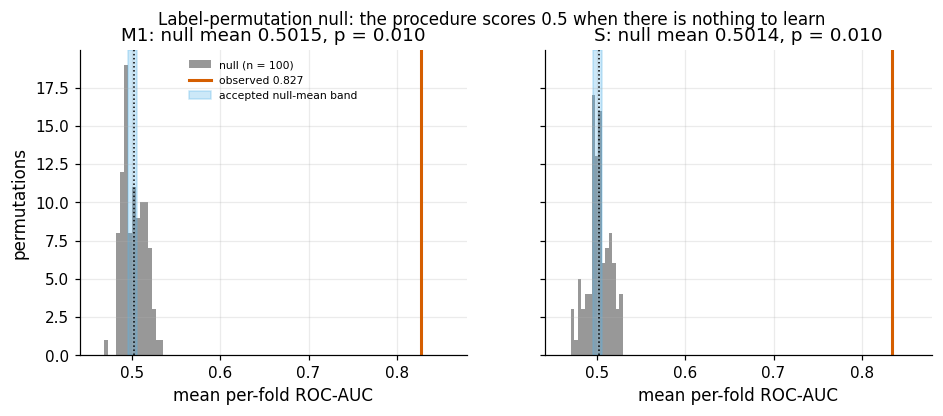

In [3]:
# Label-permutation null: refit M1 and S on permuted training labels (same folds) and collect the mean
# per-fold AUC. Reads ctx; writes results/S9/permutation.csv; asserts that the null mean lies in the accepted
# band.
t0 = time.time()
# permutations are drawn up front and refitted independently: the worker count changes the wall time only (FAST may run
# all of its permutations at once; FINAL keeps its worker count)
N_JOBS_PERM = N_JOBS if C.IS_FINAL else max(N_JOBS, min(C.N_PERM, (os.cpu_count() or 2) - 2))
# Per arm: the observed mean AUC, the permutation null and the permutation p-value.
PERM = {arm: RB.permutation_null(ctx, Spec(arm), n_perm=C.N_PERM, seed_=RB.seed("perm", arm), n_jobs=N_JOBS_PERM)
        for arm in RB.ADMISSIBLE_ARMS}
# in_band: with a leak-free procedure the null mean must sit at 0.5 up to Monte-Carlo noise, hence the band
# [0.495, 0.505] fixed in advance (RB.PERM_NULL_BAND).
perm_tab = pd.DataFrame([dict(arm=a, observed=d["observed"], null_mean=d["null_mean"], null_sd=d["null_sd"],
                              null_min=d["null"].min(), null_max=d["null"].max(), p_value=d["p_value"], n_perm=d["n_perm"],
                              in_band=RB.PERM_NULL_BAND[0] <= d["null_mean"] <= RB.PERM_NULL_BAND[1])
                         for a, d in PERM.items()])
perm_tab.to_csv(OUT / "permutation.csv", index=False)
show(perm_tab, 4)
print(f"{sum(len(ctx.folds) * (d['n_perm'] + 1) for d in PERM.values())} fits in {time.time() - t0:.0f} s")
# Procedural-leakage guard (e.g. preprocessing fitted on test rows, label-derived weights).
assert perm_tab["in_band"].all(), "permutation null mean outside [0.495, 0.505]: procedural leakage suspected"

# Figure: permutation null of each arm (histogram) with the observed AUC (red) and the accepted band.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (arm, d) in zip(axes, PERM.items()):
    ax.hist(d["null"], bins=15, color=OI["grey"], alpha=0.8, label=f"null (n = {d['n_perm']})")
    ax.axvline(d["observed"], color=OI["vermillion"], lw=2, label=f"observed {d['observed']:.3f}")
    ax.axvspan(*RB.PERM_NULL_BAND, color=OI["sky"], alpha=0.3, label="accepted null-mean band")
    ax.axvline(d["null_mean"], color="k", ls=":", lw=1)
    ax.set(title=f"{arm}: null mean {d['null_mean']:.4f}, p = {d['p_value']:.3f}", xlabel="mean per-fold ROC-AUC")
    # Same x range in both panels, wide enough for the null (near 0.5) and for the observed AUC.
    ax.set_xlim(0.44, 0.88)
axes[0].set_ylabel("permutations")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Label-permutation null: the procedure scores 0.5 when there is nothing to learn", fontsize=11)
plots.savefig(fig, "S9_permutation_null", caption="F9-1. Mean per-fold ROC-AUC of M1 and S refitted on permuted training labels "
              f"({C.N_PERM} permutations, same folds; grey) against the observed value (red). Blue band = acceptance range "
              "[0.495, 0.505] for the null mean; dotted line = null mean. Training part, Tier 1, E-ALL.")
plt.show()
S9["permutation"] = perm_tab.set_index("arm").to_dict("index")

### 2.2 Pure-noise feature
**Why.** An appended N(0, 1) column must look like noise (interval covering 0, no AUC change, never a tree split).

In [4]:
# Pure-noise control: append an N(0, 1) column to M1 and S and check that it behaves like noise (coefficient
# interval covers 0, AUC unchanged, never used by a tree). Writes results/S9/noise_feature.csv; asserts both.
rng = np.random.default_rng(RB.seed("noise"))
# Extra columns live in the context and are appended to the raw frame by name (Spec.extra).
ctx.extras["noise_n01"] = rng.standard_normal(ctx.n)
noise_rows, NOISE_CB = [], {}
for arm in RB.ADMISSIBLE_ARMS:
    sp = Spec(arm, extra=("noise_n01",))
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    # Bootstrap of the coefficients (B refits of the whole pipeline, with the arm's fit weights). `sp=sp` pins
    # the loop variable inside the lambda.
    cb = ek.coef_bootstrap(lambda sp=sp: RB.make_pipe(sp, ctx.C0), X_, y_.astype(int), n_boot=B_COEF9,
                           seed=RB.seed("noise-coef", arm), fit_params=None if sw_ is None else {"model__sample_weight": sw_},
                           n_jobs=N_JOBS)
    NOISE_CB[arm] = cb
    s = cb.summary.loc["noise_n01"]
    sdz = float(RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)["noise_n01"].std())   # per-SD scale of the design column
    # AUC change caused by the noise column: with-noise minus without-noise, same engine as the reference.
    cmp_ = pair(sp, Spec(arm), tag=f"noise-{arm}")
    # Refit depth-3 and depth-4 trees on every fold and count in how many of them the noise column is used.
    tr_ = RB.tree_features_used(ctx, Spec(arm, model="tree", extra=("noise_n01",)), ctx.folds, "noise_n01")
    tr4 = RB.tree_features_used(ctx, Spec(arm, model="tree", depth=4, extra=("noise_n01",)), ctx.folds, "noise_n01")
    zt = (cb.summary["coef"] / cb.summary["sd"]).abs()                                # bootstrap |z| for a scale-free rank
    rank = int(zt.rank(ascending=False)["noise_n01"])
    noise_rows.append(dict(arm=arm, coef_per_sd=s["coef"] * sdz, q_low=s["q_low"] * sdz, q_high=s["q_high"] * sdz,
                           ci_covers_0=bool(s["q_low"] <= 0 <= s["q_high"]), abs_z_rank=f"{rank}/{len(cb.summary)}", abs_z=float(zt["noise_n01"]),
                           dAUC_eall=cmp_[0]["est"], dAUC_eall_lo=cmp_[0]["lo"], dAUC_eall_hi=cmp_[0]["hi"],
                           dAUC_eall_verdict=RB.equivalence_verdict(cmp_[0]["lo"], cmp_[0]["hi"]),
                           tree3_uses=int(tr_["uses_feature"].sum()), tree4_uses=int(tr4["uses_feature"].sum()),
                           n_trees=len(tr_)))
noise_tab = pd.DataFrame(noise_rows)
noise_tab.to_csv(OUT / "noise_feature.csv", index=False)
show(noise_tab, 4)
# Overfitting guard: the noise coefficient interval must cover 0 and no depth-3 tree may split on the column.
assert noise_tab["ci_covers_0"].all() and (noise_tab["tree3_uses"] == 0).all()
S9["noise_feature"] = noise_tab.set_index("arm").to_dict("index")

arm,coef_per_sd,q_low,q_high,ci_covers_0,abs_z_rank,abs_z,dAUC_eall,dAUC_eall_lo,dAUC_eall_hi,dAUC_eall_verdict,tree3_uses,tree4_uses,n_trees
M1,0.0118,-0.0753,0.1100,True,43/47,0.2574,-0.0000,-0.0009,0.0009,supported,0,0,26
S,0.0482,-0.0668,0.1691,True,30/43,0.7934,-0.0001,-0.0008,0.0005,supported,0,4,26


### 2.3 Positive control
**Why.** A synthetic column z = d·y + N(0, 1) with known AUC 0.60 must be recovered and its increment detected.

In [5]:
# Positive control: add a synthetic column with a known single-feature AUC of 0.60 (z = d * y + N(0, 1)) and
# check that the procedure recovers that AUC and detects the increment. Writes
# results/S9/positive_control.csv.
ctx.extras["pos_control"] = RB.signal_feature(ctx.y, RB.POS_CONTROL_AUC, seed_=RB.seed("positive-control"))
# Single-feature AUC of z with a bootstrap interval; the design value (0.60) must lie inside it.
z_auc = RB.auc_ci(ctx.y, ctx.extras["pos_control"].to_numpy(), seed_=RB.seed("z-auc"))
print(f"single-feature AUC of z: {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}] (design value {RB.POS_CONTROL_AUC:.2f})")
pos_rows = []
for arm in RB.ADMISSIBLE_ARMS:
    for r in pair(Spec(arm, extra=("pos_control",)), Spec(arm), tag=f"pos-{arm}"):
        pos_rows.append(dict(arm=arm, pop=r["pop"], auc_without=r["auc_b"], auc_with=r["auc_a"], est=r["est"], lo=r["lo"],
                             hi=r["hi"], interval=r["interval"], detected=bool(r["lo"] > 0)))
# detected = the lower bound of the interval for the AUC gain is above 0.
pos_tab = pd.DataFrame(pos_rows)
pos_tab.to_csv(OUT / "positive_control.csv", index=False)
show(pos_tab, 4)
# The control only means something if z really has the intended AUC.
assert z_auc[1] <= RB.POS_CONTROL_AUC <= z_auc[2], "positive-control AUC not recovered"
# Power guard: a weak real signal must be detected on E-ALL, otherwise the negative controls could pass merely
# because the procedure is blind.
assert pos_tab.loc[pos_tab["pop"] == "E-ALL", "detected"].all(), "positive control not detected on E-ALL"
S9["positive_control"] = dict(z_auc=z_auc, rows=pos_tab.to_dict("records"))

single-feature AUC of z: 0.588 [0.567, 0.610] (design value 0.60)


arm,pop,auc_without,auc_with,est,lo,hi,interval,detected
M1,E-ALL,0.8285,0.8345,0.0061,0.0023,0.0101,bootstrap,True
M1,E-SCREEN,0.7723,0.7844,0.0122,0.0019,0.0228,bootstrap,True
S,E-ALL,0.8359,0.8420,0.0061,0.0021,0.0102,bootstrap,True
S,E-SCREEN,0.7807,0.7939,0.0132,0.0026,0.0242,bootstrap,True


## 3 Seed stability
**Why.** Ten seeds derived from `SEED_MASTER` draw new folds and bootstrap streams (FAST: five); the H2b(a) verdict must
not depend on them.

10 seeds x 2 arms x 25 folds in 46 s


seed_index,pop,auc_a,auc_b,est,lo,hi,interval,h2b
0,E-ALL,0.8355,0.8287,0.0069,-0.0018,0.0155,corrected_t,inconclusive
0,E-SCREEN,0.7805,0.7739,0.0066,-0.0084,0.0222,bootstrap,inconclusive
1,E-ALL,0.8354,0.8290,0.0060,-0.0013,0.0133,corrected_t,inconclusive
1,E-SCREEN,0.7814,0.7735,0.0080,-0.0082,0.0224,bootstrap,inconclusive
2,E-ALL,0.8364,0.8297,0.0068,0.0005,0.0131,corrected_t,inconclusive
2,E-SCREEN,0.7834,0.7749,0.0086,-0.0072,0.0230,bootstrap,inconclusive
3,E-ALL,0.8352,0.8284,0.0071,0.0002,0.0140,corrected_t,inconclusive
3,E-SCREEN,0.7818,0.7746,0.0072,-0.0079,0.0223,bootstrap,inconclusive
4,E-ALL,0.8347,0.8271,0.0078,0.0014,0.0143,corrected_t,inconclusive
4,E-SCREEN,0.7816,0.7712,0.0104,-0.0054,0.0248,bootstrap,inconclusive


,est_min,est_max,est_sd,lo_min,hi_max,verdicts
pop,,,,,,
E-ALL,0.0058,0.0078,0.0006,-0.0018,0.0155,inconclusive x10
E-SCREEN,0.0062,0.0104,0.0012,-0.0090,0.0248,inconclusive x10


E-ALL verdict identical under all seeds: True (reference: inconclusive)


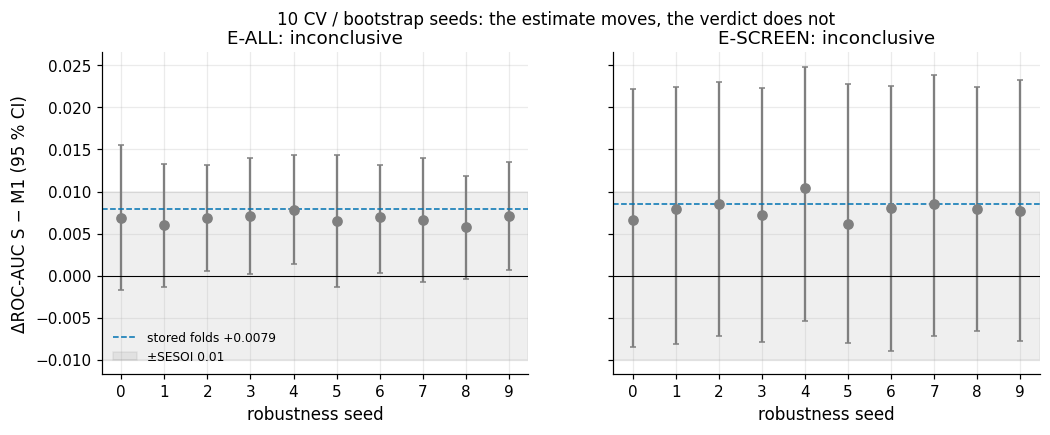

In [6]:
# Seed stability: redo the S - M1 comparison with new folds and bootstrap streams (data, hold-out and C0
# fixed). Reads ctx; writes results/S9/seed_stability.csv. The verdict must not depend on the seed. Fit many
# (spec, folds) pairs in one parallel batch; pair() later finds them in the cache.
def prefetch(items):
    """Run many (spec, folds) pairs in one parallel batch (fills the cache used by `pair`)."""
    t0 = time.time()
    RB.run_jobs(ctx, items, n_jobs=N_JOBS, cache=RUNS)
    return time.time() - t0

# One fresh repeated stratified fold set per robustness seed, derived from the master seed.
SEED_FOLDS = {k: RB.seed_folds(ctx.strat, RB.seed("cv-seed", k)) for k in range(N_SEEDS)}
secs = prefetch({f"{a}{k}": (Spec(a), f) for k, f in SEED_FOLDS.items() for a in RB.ADMISSIBLE_ARMS})
seed_rows = []
for k, f in SEED_FOLDS.items():
    for r in pair(Spec("S"), Spec("M1"), f, tag=f"seed{k}"):
        seed_rows.append(dict(seed_index=k, seed=f.seed, folds_hash=f.hash[:12], **{c: r[c] for c in
                              ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(OUT / "seed_stability.csv", index=False)
print(f"{len(SEED_FOLDS)} seeds x 2 arms x {len(ctx.folds)} folds in {secs:.0f} s")
show(seeds[["seed_index", "pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]], 4)
# Spread of the estimates and verdict counts per population.
seed_sum = seeds.groupby("pop").agg(est_min=("est", "min"), est_max=("est", "max"), est_sd=("est", "std"),
                                    lo_min=("lo", "min"), hi_max=("hi", "max"),
                                    verdicts=("h2b", lambda v: ", ".join(f"{k} x{n}" for k, n in v.value_counts().items())))
display(seed_sum.round(4))
# Stable = all seeds give one and the same E-ALL verdict.
seed_stable = seeds.loc[seeds["pop"] == "E-ALL", "h2b"].nunique() == 1
ref_v = S9["reference"]["E-ALL"]["h2b"]
print(f"E-ALL verdict identical under all seeds: {seed_stable} (reference: {ref_v})")

# Figure: one interval per seed. Colour = verdict under the locked equivalence rule.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
# Verdict colours shared by the figures of this section.
VCOL = {"supported": OI["green"], "refuted": OI["vermillion"], "inconclusive": OI["grey"]}
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = seeds[seeds["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.errorbar(i, r["est"], yerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o", color=VCOL[r["h2b"]], capsize=2)
    rr = S9["reference"][pop]
    ax.axhline(rr["est"], color=OI["blue"], ls="--", lw=1, label=f"stored folds {rr['est']:+.4f}")
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12, label="±SESOI 0.01")
    ax.axhline(0, color="k", lw=0.7)
    ax.set(xticks=range(len(s)), xlabel="robustness seed", title=f"{pop}: {', '.join(s['h2b'].value_counts().index)}")
axes[0].set_ylabel("ΔROC-AUC S − M1 (95 % CI)")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle(f"{len(SEED_FOLDS)} CV / bootstrap seeds: the estimate moves, the verdict does not", fontsize=11)
plots.savefig(fig, "S9_seed_stability", caption=f"F9-3. ΔROC-AUC (S − M1, Tier 1) with its conservative 95 % CI under {len(SEED_FOLDS)} robustness seeds "
              "(new repeated stratified folds and bootstrap streams; data, hold-out and C0 fixed). Colour = verdict under the locked "
              "equivalence rule (grey = inconclusive); dashed = stored folds of the run mode.")
plt.show()
S9["seeds"] = dict(n=len(SEED_FOLDS), stable_eall=bool(seed_stable), summary=seed_sum.to_dict("index"))

## 4 Sensitivity table
**Why.** Many analysis choices were made once. Each of 16 pre-specified variations changes **one** choice for **both**
arms and recomputes ΔAUC(S − M1) with the same engine: labels SL1 (HbA1c only), SL2 (self-report only), SL3 (borderline
positive), SL4 (treatment-aware), SL5 (NCHS incl. fasting glucose, fasting subsample); survey weights in neither or both
fits; `IterativeImputer` or complete cases; Tier 2; C ∈ {0.01, 1, 10}; a depth-4 tree; race as a feature (excluded by
design in §1); and M1 with its **own** tuned C.

In [7]:
# Sensitivity table: change ONE analysis choice at a time (label, weights, imputation, tier, C, tree depth,
# race, own C) for both arms and recompute delta AUC(S - M1). Writes results/S9/sensitivity_table.csv. Also
# tunes C for M0 and M1 separately and runs the leak gate (M1 - M0) with each setting.
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

# row subsets and extra columns used by the specifications
# Apply only the stateless preparation steps (nothing is fitted), so no information from y enters the masks
# below.
pre = Pipeline([s for s in P.preprocessor_steps(P.ARMS["S"], 1) if s[0] in ("p01", "p02", "p03", "no_care", "p04")])
pre_frame = pre.fit(ctx.X[1]).transform(ctx.X[1])          # stateless steps only: nothing is learned from y
# Complete cases = rows without any missing Tier-1 input after aggregation.
ctx.subsets["complete"] = pre_frame.notna().all(axis=1).to_numpy()
# Fasting subsample = rows where the fasting-glucose label SL5 is defined.
ctx.subsets["fasting"] = ctx.labels["SL5"].notna().to_numpy()
# Race as a string column for the 'race as a feature' variation (excluded by design in the main models, §1).
ctx.extras["race_feature"] = ctx.cl["race"].astype(str).astype(object).to_numpy()
print(f"complete cases (no missing Tier-1 input after aggregation): {ctx.subsets['complete'].sum():,} of {ctx.n:,}; "
      f"fasting subsample: {ctx.subsets['fasting'].sum():,} rows, {int(ctx.labels['SL5'].sum())} SL5 positives")

def tune_C(arm):
    """LogisticRegressionCV over the C grid on the arm's own design (the S7 C0 procedure, applied to the arm)."""
    sp = Spec(arm)
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    design = RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)
    # Inner 5-fold CV on the training part, seeded per arm: C is chosen by inner-CV AUC.
    inner = StratifiedKFold(5, shuffle=True, random_state=RB.seed("ownC", arm))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lrcv = LogisticRegressionCV(Cs=list(RB.C_GRID), cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                    class_weight=P.model_kwargs(P.ARMS[arm])["class_weight"], l1_ratios=(0.0,),
                                    use_legacy_attributes=False, n_jobs=N_JOBS)
        lrcv.fit(design, y_.astype(int), sample_weight=sw_)
    # Mean inner-CV AUC for each C of the grid (average over the 5 inner folds).
    sc = np.asarray(lrcv.scores_).reshape(5, -1).mean(axis=0).ravel()[:len(RB.C_GRID)]
    return float(np.ravel(lrcv.C_)[0]), {str(c): round(float(v), 4) for c, v in zip(RB.C_GRID, sc)}

# Tune C separately for M0 and M1: tests whether using the C0 tuned on S for every arm favoured S.
OWN_C = {arm: tune_C(arm) for arm in ("M0", "M1")}
for arm, (c_, sc) in OWN_C.items():
    print(f"{arm}: own C = {c_}  (inner-CV AUC by C {sc}; C0 = {ctx.C0} was tuned on S)")

# Each row changes one choice for both arms: (name, group, spec for S, spec for M1, label used on E-ALL). S is
# survey-weighted by default and M1 is not, so the two weighting rows each force the setting on one arm.
SENS = [  # (name, group, spec S, spec M1, E-ALL label)
    ("SL1 HbA1c only", "label", Spec("S", label="SL1"), Spec("M1", label="SL1"), "SL1"),
    ("SL2 self-report only", "label", Spec("S", label="SL2"), Spec("M1", label="SL2"), "SL2"),
    ("SL3 borderline positive", "label", Spec("S", label="SL3"), Spec("M1", label="SL3"), "SL3"),
    ("SL4 treatment-aware", "label", Spec("S", label="SL4"), Spec("M1", label="SL4"), "SL4"),
    ("SL5 NCHS incl. FPG (fasting)", "label", Spec("S", label="SL5", rows="fasting"), Spec("M1", label="SL5", rows="fasting"), "SL5"),
    ("unweighted fit (both)", "weights", Spec("S", weighted=False), Spec("M1"), "L_comb"),
    ("survey-weighted fit (both)", "weights", Spec("S"), Spec("M1", weighted=True), "L_comb"),
    ("IterativeImputer", "imputation", Spec("S", impute="iterative"), Spec("M1", impute="iterative"), "L_comb"),
    ("complete cases", "imputation", Spec("S", rows="complete"), Spec("M1", rows="complete"), "L_comb"),
    ("Tier 2 (+ lipids)", "tier", Spec("S", tier=2), Spec("M1", tier=2), "L_comb"),
    ("C = 0.01", "C", Spec("S", C=0.01), Spec("M1", C=0.01), "L_comb"),
    ("C = 1", "C", Spec("S", C=1.0), Spec("M1", C=1.0), "L_comb"),
    ("C = 10", "C", Spec("S", C=10.0), Spec("M1", C=10.0), "L_comb"),
    ("depth-4 tree", "model", Spec("S", model="tree", depth=4), Spec("M1", model="tree", depth=4), "L_comb"),
    ("race as a feature", "features", Spec("S", extra=("race_feature",)), Spec("M1", extra=("race_feature",)), "L_comb"),
    ("M1 with its own tuned C", "C", Spec("S"), Spec("M1", C=OWN_C["M1"][0]), "L_comb"),
]
# The pre-specified list has at most 16 variations (the text quotes 16).
assert len(SENS) <= 16
# Specs for the leak gate with each arm's own C; they are prefetched together with the table.
own_gate = [Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), Spec("M0")]
# Fit every specification of the table and of the gate in one parallel batch.
secs = prefetch({f"{i}{j}": (sp, ctx.folds) for i, row in enumerate(SENS) for j, sp in enumerate(row[2:4])}
                | {f"g{j}": (sp, ctx.folds) for j, sp in enumerate(own_gate)})
# Start with the reference row so every variation can be read against it.
sens_rows = [dict(spec="reference (S7)", group="reference", **r) for r in ref]
for name, grp, sa, sb, lab in SENS:
    for r in pair(sa, sb, tag=f"sens-{name}", label=lab):
        sens_rows.append(dict(spec=name, group=grp, **r))
sens = pd.DataFrame(sens_rows)
# True where a variation gives the same H2b(a) verdict as the reference for that population.
sens["same_verdict_as_reference"] = [v == S9["reference"][p]["h2b"] for v, p in zip(sens["h2b"], sens["pop"])]
sens.to_csv(OUT / "sensitivity_table.csv", index=False)
print(f"{len(SENS)} specifications, {secs:.0f} s")
show(sens[["spec", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]], 4)

# Leak gate: AUC(M1) - AUC(M0), where M0 keeps the inadmissible columns. The gap measures how much of the
# naive performance came from inadmissible items. Computed with each arm's own C and, below, with the shared
# C0.
gate_own = pair(Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), tag="gate-ownC")
gate_c0 = pair(Spec("M1"), Spec("M0"), tag="gate-C0")
for g, nm in ((gate_c0, "C0 for both"), (gate_own, "own C each")):
    print(f"leak gate M1 - M0 ({nm}): " + "; ".join(f"{r['pop']} {r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]" for r in g))

eall = sens[sens["pop"] == "E-ALL"]
n_same = int(eall["same_verdict_as_reference"].sum())
print(f"E-ALL: {n_same} of {len(eall)} rows share the reference verdict ({ref_v}); "
      f"differing: {eall.loc[~eall['same_verdict_as_reference'], 'spec'].tolist()}")
esc_ = sens[sens["pop"] == "E-SCREEN"]
print(f"E-SCREEN verdicts: {esc_['h2b'].value_counts().to_dict()}; estimates {esc_['est'].min():+.3f} to {esc_['est'].max():+.3f}")
print(f"sign: E-ALL estimates {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; "
      f"rows with CI wholly below 0: {int((sens['hi'] < 0).sum())}")

complete cases (no missing Tier-1 input after aggregation): 3,621 of 4,584; fasting subsample: 2,338 rows, 454 SL5 positives


M0: own C = 0.1  (inner-CV AUC by C {'0.01': 0.9536, '0.1': 0.9575, '1.0': 0.9561, '10.0': 0.9552}; C0 = 0.1 was tuned on S)
M1: own C = 0.1  (inner-CV AUC by C {'0.01': 0.8263, '0.1': 0.828, '1.0': 0.8273, '10.0': 0.8272}; C0 = 0.1 was tuned on S)


16 specifications, 90 s


spec,pop,n_eval,n_pos,auc_a,auc_b,est,lo,hi,interval,h2b
reference (S7),E-ALL,4584,777,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,inconclusive
reference (S7),E-SCREEN,3934,127,0.7807,0.7723,0.0085,-0.0081,0.0236,bootstrap,inconclusive
SL1 HbA1c only,E-ALL,4584,582,0.8316,0.8206,0.0116,0.0002,0.0230,corrected_t,inconclusive
SL1 HbA1c only,E-SCREEN,3934,127,0.7845,0.7796,0.0049,-0.0124,0.0214,bootstrap,inconclusive
SL2 self-report only,E-ALL,4584,650,0.8389,0.8329,0.0062,-0.0035,0.0160,corrected_t,inconclusive
SL2 self-report only,E-SCREEN,3934,127,0.7668,0.7587,0.0081,-0.0087,0.0245,bootstrap,inconclusive
SL3 borderline positive,E-ALL,4584,920,0.8254,0.8193,0.0061,0.0001,0.0121,corrected_t,inconclusive
SL3 borderline positive,E-SCREEN,3934,127,0.7763,0.7708,0.0055,-0.0090,0.0214,bootstrap,inconclusive
SL4 treatment-aware,E-ALL,4584,712,0.8384,0.8306,0.0079,0.0001,0.0158,corrected_t,inconclusive
SL4 treatment-aware,E-SCREEN,3934,127,0.7825,0.7732,0.0093,-0.0078,0.0253,bootstrap,inconclusive


leak gate M1 - M0 (C0 for both): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.109, -0.032]
leak gate M1 - M0 (own C each): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.113, -0.030]
E-ALL: 17 of 17 rows share the reference verdict (inconclusive); differing: []
E-SCREEN verdicts: {'inconclusive': 17}; estimates -0.012 to +0.020
sign: E-ALL estimates -0.0061 to +0.0116; rows with CI wholly below 0: 0


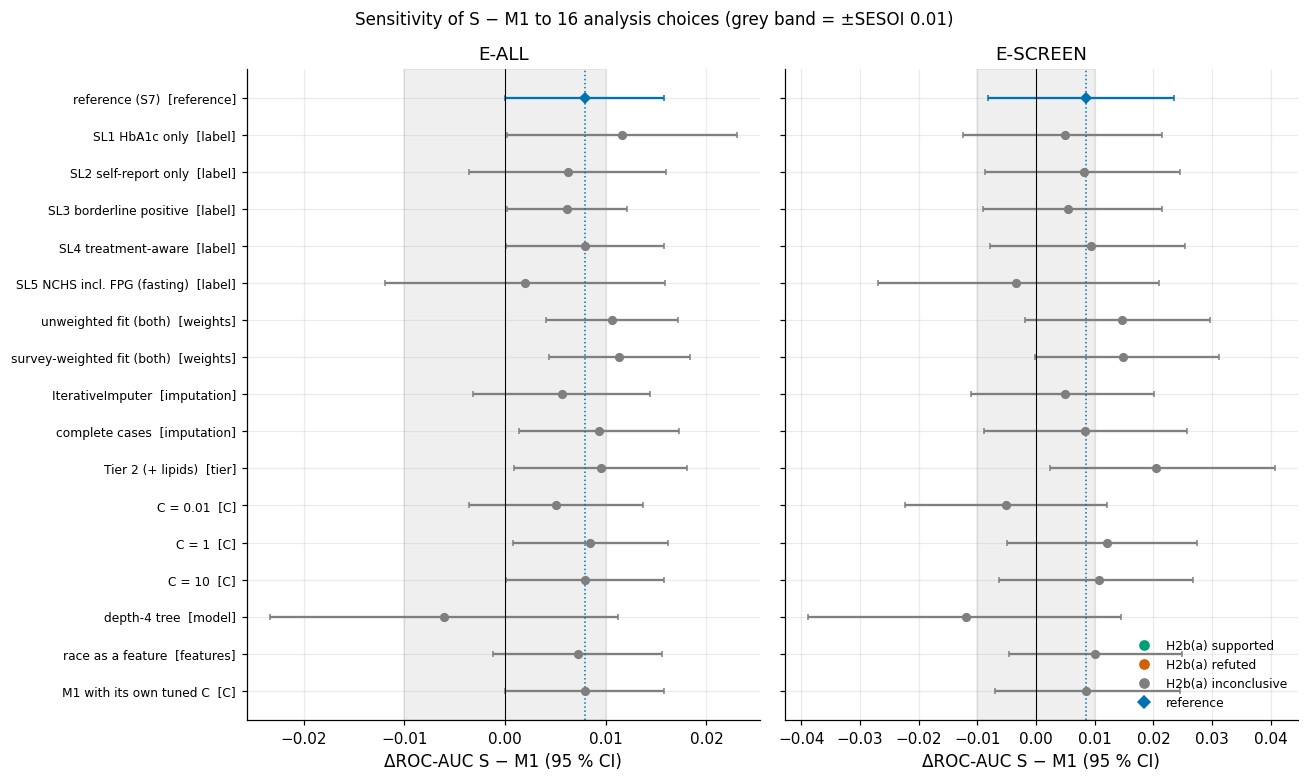

In [8]:
# Forest plot of the sensitivity table: one row per specification, E-ALL left and E-SCREEN right. Reads
# `sens`; writes the figure through plots.savefig.
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), sharey=True)
# Keep the table order (reference first); dict.fromkeys removes duplicates and preserves order.
order = list(dict.fromkeys(sens["spec"]))
groups_ = sens.drop_duplicates("spec").set_index("spec")["group"]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = sens[sens["pop"] == pop].set_index("spec").loc[order]
    # Row 0 is the reference (blue diamond); the other rows are coloured by their H2b(a) verdict.
    for i, (nm, r) in enumerate(s.iterrows()):
        ax.errorbar(r["est"], i, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="D" if i == 0 else "o",
                    color=OI["blue"] if i == 0 else VCOL[r["h2b"]], capsize=2, ms=5)
    # Grey band = +-SESOI (0.01), the equivalence margin of the locked rule.
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(s["est"].iloc[0], color=OI["blue"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1 (95 % CI)")
axes[0].set_yticks(range(len(order)), [f"{o}  [{groups_[o]}]" for o in order], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"H2b(a) {v}") for v, c in VCOL.items()]
               + [Line2D([], [], marker="D", ls="", color=OI["blue"], label="reference")], fontsize=8, loc="lower right")
fig.suptitle("Sensitivity of S − M1 to 16 analysis choices (grey band = ±SESOI 0.01)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_sensitivity_forest", caption="F9-2. ΔROC-AUC (S − M1) with conservative 95 % CIs for the reference and 16 one-at-a-time "
              "variations (labels SL1-SL5, fit weights, imputation, tier, C, depth-4 tree, race as a feature, M1 with its own tuned C); "
              "left E-ALL (scored against the row's label), right E-SCREEN. Colour = H2b(a) verdict under the locked equivalence rule.")
plt.show()
S9["sensitivity"] = dict(n_specs=len(SENS), eall_same_verdict=n_same, eall_rows=len(eall),
                         own_C={a: c for a, (c, _) in OWN_C.items()},
                         leak_gate_C0={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_c0},
                         leak_gate_own_C={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_own},
                         table=sens[["spec", "group", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval",
                                     "mdd", "h2b"]].round(5).to_dict("records"))

**So what.** **The E-ALL verdict does not move**: all 16 variations give the reference verdict, and no interval lies
wholly below 0. **Labels and weighting move the estimate most**: weighting both arms alike enlarges the S advantage to
about +0.01 (part of the reference gap is S's own survey weighting, B6b); the label changes the size of the gap, not
its direction. **The depth-4 tree reverses the sign** with a wide interval – for a tree the preparation steps are
irrelevant (B5-e), one more reason the tree is a probe. **Per-arm C does not favour S**: tuned on their own, M0 and M1
pick the same C as S, so the "same model for every arm" rule neither favoured S nor manufactured the leak gate. This is
a fairness-across-arms check, not a test of nesting (C0 was chosen once on the whole training part); the approximate
nested check is in §9.12. On E-SCREEN every verdict is inconclusive (about 25 positives per fold).

## 5 Specification curve
**Why.** A specification curve (Simonsohn et al. 2020) crosses label × weighting × C: 60 specifications (FAST: 30).

In [9]:
# Specification curve: cross 5 training labels x 3 weighting schemes x the values of C (60 specifications in
# FINAL mode, 30 in FAST) and recompute delta AUC(S - M1) for each. Writes results/S9/specification_curve.csv.
import itertools
# Table name -> Spec.label; 'arm' keeps each arm's own training label (the main label), SL1-SL4 impose the
# same sensitivity label on both arms.
LABELS_SC = {"L_comb": "arm", "SL1": "SL1", "SL2": "SL2", "SL3": "SL3", "SL4": "SL4"}
# 'as specified' keeps each arm's own default (S weighted, M1 not); the other two force both arms alike.
WEIGHTING = ("as specified", "both unweighted", "both weighted")
grid = []
for (lab, lab_spec), wt, c in itertools.product(LABELS_SC.items(), WEIGHTING, C_CURVE):
    # None means 'use the frozen C0', so the C0 column reproduces the reference settings.
    cc = None if c == ctx.C0 else c
    # weighted=False forces S unweighted; None keeps S's own weighting. For M1, weighted=True forces survey
    # weights.
    sa = Spec("S", label=lab_spec, C=cc, weighted=False if wt == "both unweighted" else None)
    sb = Spec("M1", label=lab_spec, C=cc, weighted=True if wt == "both weighted" else None)
    grid.append(dict(label=lab, weighting=wt, C=c, sa=sa, sb=sb))
# 5 labels x 3 weightings x 4 values of C = 60 (FAST: 2 values of C = 30).
assert len(grid) == S9["n_curve"] == (60 if C.IS_FINAL else 30)
secs = prefetch({f"sc{i}{j}": (g[k], ctx.folds) for i, g in enumerate(grid) for j, k in enumerate(("sa", "sb"))})
sc_rows = []
for i, g in enumerate(grid):
    for r in pair(g["sa"], g["sb"], tag=f"curve{i}", label=g["label"]):
        sc_rows.append(dict(spec_id=i, label=g["label"], weighting=g["weighting"], C=g["C"], **{k: r[k] for k in
                            ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
curve = pd.DataFrame(sc_rows)
curve.to_csv(OUT / "specification_curve.csv", index=False)
print(f"{len(grid)} specifications x 2 arms in {secs:.0f} s")
# Per population: how many specifications put S ahead (est > 0), have an interval wholly above 0 (lo > 0),
# wholly below 0 (hi < 0) or beyond the SESOI (lo >= 0.01).
cs = curve.groupby("pop").agg(n=("est", "size"), est_median=("est", "median"), est_min=("est", "min"), est_max=("est", "max"),
                              share_positive=("est", lambda v: (v > 0).mean()),
                              share_ci_above_0=("lo", lambda v: (v > 0).mean()),
                              share_ci_below_0=("hi", lambda v: (v < 0).mean()),
                              share_beyond_sesoi=("lo", lambda v: (v >= C.SESOI["roc_auc"]).mean()))
display(cs.round(3))
display(curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0))
print("median E-ALL estimate by factor:")
for fac in ("label", "weighting", "C"):
    print("  ", curve[curve["pop"] == "E-ALL"].groupby(fac)["est"].median().round(4).to_dict())

60 specifications x 2 arms in 97 s


,n,est_median,est_min,est_max,share_positive,share_ci_above_0,share_ci_below_0,share_beyond_sesoi
pop,,,,,,,,
E-ALL,60,0.010,0.005,0.018,1.00,0.85,0.0,0.0
E-SCREEN,60,0.012,-0.011,0.021,0.75,0.30,0.0,0.0


h2b,inconclusive
pop,
E-ALL,60
E-SCREEN,60


median E-ALL estimate by factor:
   {'L_comb': 0.0098, 'SL1': 0.0146, 'SL2': 0.01, 'SL3': 0.0079, 'SL4': 0.0104}
   {'as specified': 0.0074, 'both unweighted': 0.0105, 'both weighted': 0.0113}
   {0.01: 0.009, 0.1: 0.0103, 1.0: 0.0109, 10.0: 0.0108}


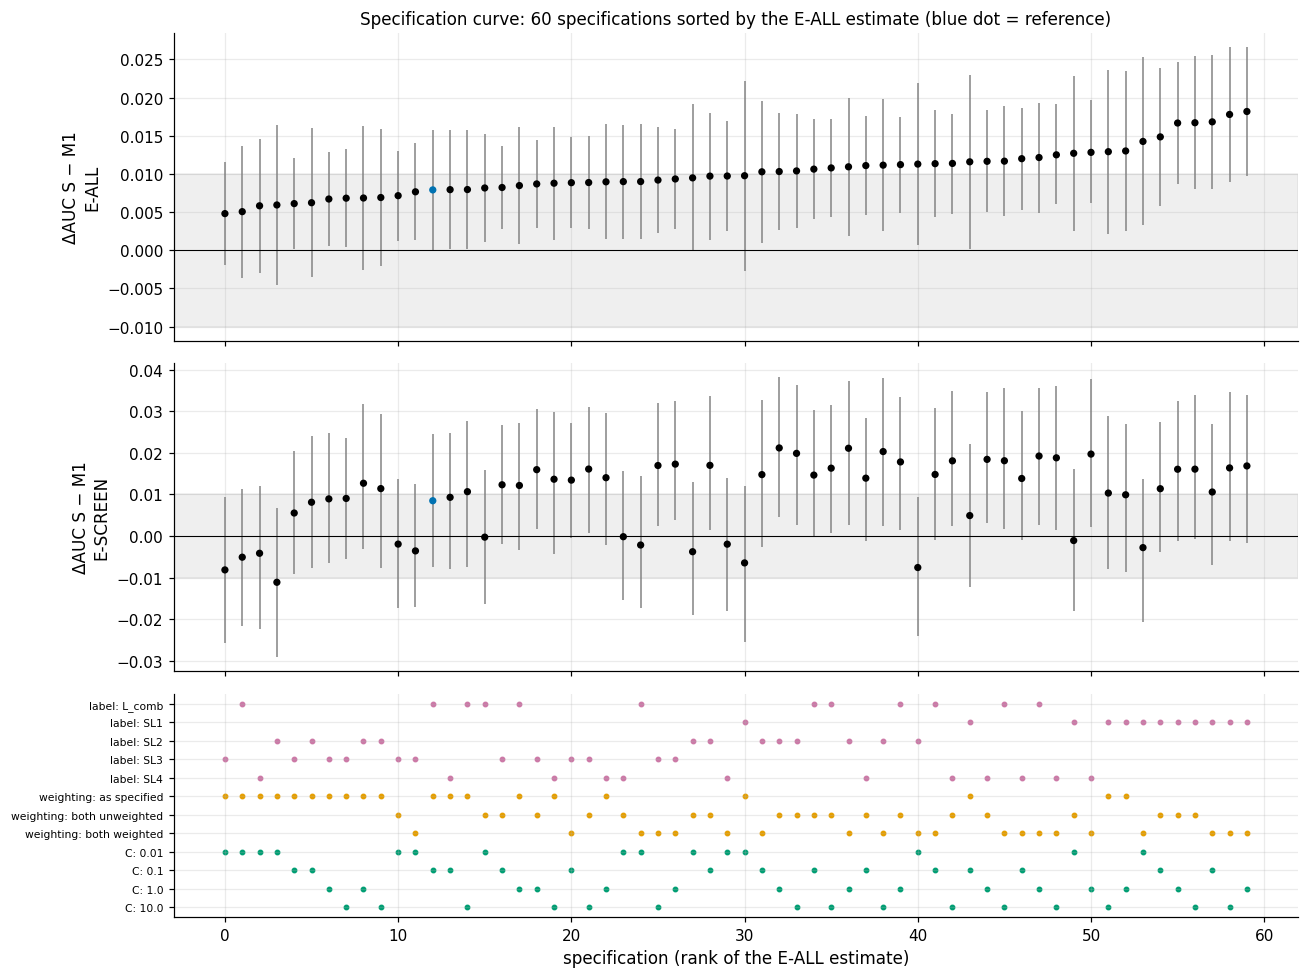

In [10]:
# Specification-curve figure: specifications sorted by the E-ALL estimate (top), the same order on E-SCREEN
# (middle) and the choices that define each specification (bottom).
e_all = curve[curve["pop"] == "E-ALL"].sort_values("est").reset_index(drop=True)
order_ids = e_all["spec_id"].tolist()
# Reorder the E-SCREEN rows by the E-ALL order so that the three panels line up.
e_scr = curve[curve["pop"] == "E-SCREEN"].set_index("spec_id").loc[order_ids].reset_index()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [2.2, 2.2, 1.6]})
for ax, d, pop in ((axes[0], e_all, "E-ALL"), (axes[1], e_scr, "E-SCREEN")):
    x = np.arange(len(d))
    ax.vlines(x, d["lo"], d["hi"], color=[VCOL[v] for v in d["h2b"]], lw=1.2, alpha=0.8)
    ax.scatter(x, d["est"], s=14, color=[OI["blue"] if (l == "L_comb" and w == "as specified" and c == ctx.C0) else "k"
                                          for l, w, c in zip(d["label"], d["weighting"], d["C"])], zorder=3)
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_ylabel(f"ΔAUC S − M1\n{pop}")
axes[0].set_title(f"Specification curve: {len(grid)} specifications sorted by the E-ALL estimate (blue dot = reference)", fontsize=11)
ax = axes[2]
# One indicator row per factor level; a dot marks each specification that uses that level.
rows_ind = [("label", l) for l in LABELS_SC] + [("weighting", w) for w in WEIGHTING] + [("C", c) for c in C_CURVE]
for j, (fac, val) in enumerate(rows_ind):
    hit = (e_all[fac] == val).to_numpy()
    ax.scatter(np.flatnonzero(hit), np.full(hit.sum(), j), s=8, color=OI["purple"] if fac == "label" else OI["orange"] if fac == "weighting" else OI["green"])
ax.set_yticks(range(len(rows_ind)), [f"{fac}: {val}" for fac, val in rows_ind], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("specification (rank of the E-ALL estimate)")
fig.tight_layout()
plots.savefig(fig, "S9_specification_curve", caption=f"Specification curve (extension). {len(grid)} specifications = 5 training labels x 3 weighting "
              f"schemes x {len(C_CURVE)} values of C. Top: ΔROC-AUC (S − M1) on E-ALL with conservative 95 % CI, sorted; middle: E-SCREEN in the same "
              "order; bottom: which choices define each specification. Line colour = H2b(a) verdict (grey inconclusive, green "
              "equivalent, red refuted); grey band = ±SESOI 0.01.")
plt.show()
S9["specification_curve"] = dict(n=len(grid), summary=cs.round(5).to_dict("index"),
                                 verdicts=curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0).to_dict("index"))

## 6 Survey-cluster cross-validation
**Why.** Folds grouped by stratum × PSU keep each survey cluster on one side of every split.

In [11]:
# Survey-cluster CV: rebuild the folds so that every stratum x PSU cluster stays on one side of each split,
# then repeat the S - M1 comparison. Writes results/S9/grouped_cv.csv. Cluster id = stratum * 10 + PSU (the
# masked PSU is 1 or 2 within a stratum, so the id is unique).
groups = (ctx.cl[C.STRATA].astype(int) * 10 + ctx.cl[C.PSU].astype(int)).to_numpy()
# Group-aware repeated folds with the same number of splits and repeats as the stored ones.
GFOLDS = RB.group_folds(ctx.strat, groups, RB.seed("group-cv"))
gsz = pd.DataFrame([dict(fold=i, n_test=len(te), n_clusters=len(np.unique(groups[te])), pos=int(ctx.y[te].sum()),
                         pos_escreen=int(ctx.y_esc[te][ctx.esc[te]].sum())) for i, (_, te) in enumerate(GFOLDS)])
# Guard: no cluster may appear on both the training and the test side of any split.
assert all(len(set(groups[te]) & set(groups[tr])) == 0 for tr, te in GFOLDS), "a cluster appears on both sides of a split"
print(f"{len(np.unique(groups))} strata x PSU clusters in the training part; grouped folds: n_test {gsz['n_test'].min()}-{gsz['n_test'].max()}, "
      f"clusters per test fold {gsz['n_clusters'].min()}-{gsz['n_clusters'].max()}, E-SCREEN positives {gsz['pos_escreen'].min()}-{gsz['pos_escreen'].max()}")
secs = prefetch({f"g{a}": (Spec(a), GFOLDS) for a in RB.ADMISSIBLE_ARMS})
gcv = pair(Spec("S"), Spec("M1"), GFOLDS, tag="group-cv")
# Stack the stored-fold reference and the grouped-fold result into one table for a side-by-side reading.
gcv_tab = pd.DataFrame([dict(folds="stored stratified", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in ref]
                       + [dict(folds="strata x PSU grouped", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in gcv])
gcv_tab = gcv_tab.rename(columns={"auc_a": "auc_S", "auc_b": "auc_M1"})
gcv_tab.to_csv(OUT / "grouped_cv.csv", index=False)
show(gcv_tab, 4)
# Change in the AUC of S when folds are grouped; optimism from within-cluster dependence would appear as a
# drop.
dS = {p: gcv_tab.query("folds == 'strata x PSU grouped' and pop == @p")["auc_S"].iloc[0] - gcv_tab.query("folds == 'stored stratified' and pop == @p")["auc_S"].iloc[0]
      for p in ("E-ALL", "E-SCREEN")}
print(f"AUC of S, grouped minus stratified folds: E-ALL {dS['E-ALL']:+.4f}, E-SCREEN {dS['E-SCREEN']:+.4f}")
S9["grouped_cv"] = dict(n_clusters=int(len(np.unique(groups))), table=gcv_tab.round(5).to_dict("records"),
                        auc_S_grouped_minus_stratified=dS)

30 strata x PSU clusters in the training part; grouped folds: n_test 805-1058, clusters per test fold 5-7, E-SCREEN positives 20-31


folds,pop,auc_S,auc_M1,est,lo,hi,interval,h2b
stored stratified,E-ALL,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,inconclusive
stored stratified,E-SCREEN,0.7807,0.7723,0.0085,-0.0081,0.0236,bootstrap,inconclusive
strata x PSU grouped,E-ALL,0.8313,0.8257,0.0055,-0.0001,0.0118,bootstrap,inconclusive
strata x PSU grouped,E-SCREEN,0.7797,0.7727,0.0070,-0.0086,0.0221,bootstrap,inconclusive


AUC of S, grouped minus stratified folds: E-ALL -0.0046, E-SCREEN -0.0010


## 7 Missing HbA1c: inverse-probability weights and delta adjustment
**Why.** The cohort keeps only examined adults *with* an HbA1c value. §3 showed this missingness is not MCAR (NH Black
OR about 1.85, DR-S3-04) and §5 bounded the prevalence (Manski, DR-S5-08); both deferred two analyses to here:

1. **MAR – inverse-probability weighting (IPW).** The §3 missingness model gives each cohort member a stabilised
   weight P(observed) / P(observed | x), used for the prevalence and for ΔAUC(S − M1).
2. **MNAR – delta adjustment.** People without HbA1c who report diabetes are positive; for the others the MAR
   probability of HbA1c ≥ 6.5 is shifted by δ on the log-odds scale (δ = log 3: three-fold odds among the
   unmeasured). Manski bounds bracket every δ.

In [12]:
# Missing HbA1c, MAR part: refit the missingness logit of §3 on all examined adults, build stabilised
# inverse-probability weights and recompute prevalence and delta AUC(S - M1) with them. Reads
# results/S3/missingness_or.csv; produces `coh['ipw']`, `prev_tab` and `ipw_tab`.
ex = RB.examined_population()
# True for examined adults without an HbA1c value, i.e. the people the cohort drops.
miss = ex["a1c_observed"].eq(0)
obs_fit = RB.observation_model(ex)
ci_ = obs_fit.conf_int()
# The model predicts P(observed), so the odds ratio of being MISSING is exp(-coefficient).
or_obs = pd.DataFrame({"OR_missing": np.exp(-obs_fit.params), "ci_low": np.exp(-ci_[1]), "ci_high": np.exp(-ci_[0])}).drop("const")
# Odds ratios stored by §3 for the same model, for comparison.
s3_or = pd.read_csv(C.RESULTS_DIR / "S3" / "missingness_or.csv", index_col=0)
or_cmp = or_obs.join(s3_or[["OR"]].rename(columns={"OR": "OR_missing_S3"}))
print(f"examined non-pregnant adults {len(ex):,}; without HbA1c {int(miss.sum())} ({miss.mean():.1%}); cohort {int((~miss).sum()):,}")
display(or_cmp.round(3))
# The people with an HbA1c value are exactly the analysis cohort.
assert int((~miss).sum()) == io.COHORT_N
assert abs(or_cmp.loc["NH Black", "OR_missing"] - or_cmp.loc["NH Black", "OR_missing_S3"]) < 0.1   # same model, 37 fewer rows
# Fitted P(HbA1c observed | covariates) for every examined adult.
p_obs = pd.Series(obs_fit.predict(), index=ex["SEQN"].to_numpy())
# Stabilised weight = overall P(observed) / P(observed | x): the numerator keeps the weights near 1 and limits
# their variance compared with the plain 1 / P(observed | x).
ipw_all = (~miss).mean() / p_obs                          # stabilised weight
coh = ctx.clean.copy()
coh["ipw"] = ipw_all.reindex(coh["SEQN"]).to_numpy()
coh["w_mec_ipw"] = coh[C.WEIGHT_MEC] * coh["ipw"]
# Weights of the training part only; no hold-out row is used.
ctx.ipw = coh["ipw"].to_numpy()[ctx.train_idx]
print(f"stabilised IPW in the cohort: min {coh['ipw'].min():.3f}, median {coh['ipw'].median():.3f}, "
      f"max {coh['ipw'].max():.3f}; Kish deff {sv.kish_deff(coh['ipw']):.3f}")

# Weighted prevalence of L_comb under three weightings: blood-sample weight (WTPH2YR), exam weight on the
# complete cases (WTMEC2YR) and exam weight x IPW. Intervals use the survey design.
prev_rows = []
for nm, wcol in (("WTPH2YR (blood non-response adjusted)", C.WEIGHT_PHLEB), ("WTMEC2YR (complete case)", C.WEIGHT_MEC),
                 ("WTMEC2YR x IPW", "w_mec_ipw")):
    wp = sv.weighted_prop(coh, "L_comb", weight=wcol)
    prev_rows.append(dict(weighting=nm, est=wp["est"], ci_low=wp["ci_low"], ci_high=wp["ci_high"], df=wp["df"]))
prev_tab = pd.DataFrame(prev_rows)
show(prev_tab, 4)
# The WTPH2YR prevalence must reproduce the 14.0 % reported in §1 (tolerance 0.15 percentage points).
assert abs(prev_tab.loc[0, "est"] - 0.140) < 0.0015, "WTPH2YR prevalence must reproduce 14.0 % (the §1 weighted prevalence)"

# Two uses of IPW: weights in the evaluation only (weighted AUC) and in both fit and evaluation (Spec.ipw=True
# multiplies the fit weights).
ipw_cmp = pair(Spec("S"), Spec("M1"), tag="ipw-eval", w=ctx.ipw) + pair(Spec("S", ipw=True), Spec("M1", ipw=True), tag="ipw-fit", w=ctx.ipw)
ipw_tab = pd.DataFrame([dict(variant=v, **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")})
                        for v, r in zip(["IPW evaluation"] * 2 + ["IPW fit + evaluation"] * 2, ipw_cmp)])
show(ipw_tab, 4)

examined non-pregnant adults 6,023; without HbA1c 293 (4.9%); cohort 5,730


,OR_missing,ci_low,ci_high,OR_missing_S3
age (per 10 y),0.892,0.825,0.965,0.893
female,0.940,0.738,1.196,0.948
NH Black,1.780,1.293,2.451,1.853
NH Asian,1.374,0.840,2.249,1.383
Mexican American,0.723,0.414,1.264,0.772
Other Hispanic,0.845,0.543,1.315,0.842
Other/Multi,1.245,0.785,1.974,1.244
PIR (per unit),0.821,0.754,0.894,0.820
PIR missing,1.564,1.142,2.141,1.572
BMI (per unit),0.997,0.980,1.014,0.997


stabilised IPW in the cohort: min 0.963, median 0.992, max 1.365; Kish deff 1.001


weighting,est,ci_low,ci_high,df
WTPH2YR (blood non-response adjusted),0.1404,0.1244,0.1563,15
WTMEC2YR (complete case),0.1393,0.1232,0.1553,15
WTMEC2YR x IPW,0.1402,0.1242,0.1563,15


variant,pop,auc_a,auc_b,est,lo,hi,interval,h2b
IPW evaluation,E-ALL,0.8359,0.8284,0.0079,0.0000,0.0158,corrected_t,inconclusive
IPW evaluation,E-SCREEN,0.7801,0.7717,0.0085,-0.0080,0.0252,bootstrap,inconclusive
IPW fit + evaluation,E-ALL,0.8356,0.8286,0.0072,-0.0009,0.0154,corrected_t,inconclusive
IPW fit + evaluation,E-SCREEN,0.7798,0.7706,0.0091,-0.0074,0.0249,bootstrap,inconclusive


In [13]:
# Missing HbA1c, MNAR part (delta adjustment): fit a MAR model of HbA1c >= 6.5 % among the undiagnosed on the
# training part, shift it by delta on the log-odds scale for people without HbA1c, and recompute prevalence
# and delta AUC(S - M1) over a grid of deltas, plus the Manski all-negative / all-positive bounds. Writes
# results/S9/mnar_delta_prevalence.csv, mnar_delta_auc.csv and ipw.csv.
import statsmodels.api as sm
# Drop 'self-reported diabetes': it is constant among the undiagnosed rows on which this model is fitted.
Xd_ex = RB.missingness_design(ex).drop(columns=["self-reported diabetes"])
# Row positions of the training-part cohort inside `ex`, to pick the matching covariate rows.
seq_pos = pd.Series(np.arange(len(ex)), index=ex["SEQN"].to_numpy())
tr_rows = seq_pos.reindex(ctx.cl["SEQN"]).to_numpy()
fit_rows = tr_rows[ctx.esc]                                     # training-part E-SCREEN rows (no hold-out row)
# MAR model: logit of HbA1c >= 6.5 % given the covariates, on training-part E-SCREEN rows only.
mar_fit = sm.Logit(ctx.y_esc[ctx.esc], sm.add_constant(Xd_ex.iloc[fit_rows])).fit(disp=0)
miss_idx = np.flatnonzero(miss.to_numpy())
# People without HbA1c who report diabetes count as positive; all others are 'undetermined'.
miss_self = ex["DIQ010"].eq(1).to_numpy()[miss_idx]
# MAR probability of HbA1c >= 6.5 % for each person without HbA1c (has_constant='add' forces the intercept
# column even if a selected subset has a constant column).
p_mar = mar_fit.predict(sm.add_constant(Xd_ex, has_constant="add").iloc[miss_idx]).to_numpy()
from sklearn.metrics import roc_auc_score
print(f"MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on {len(fit_rows):,} training-part E-SCREEN rows "
      f"({int(ctx.y_esc[ctx.esc].sum())} positives), in-sample AUC {roc_auc_score(ctx.y_esc[ctx.esc], mar_fit.predict()):.3f}")
print(f"missing rows: {len(miss_idx)}; self-reported diabetes {int(miss_self.sum())}; undetermined {int((~miss_self).sum())}, "
      f"mean MAR probability {p_mar[~miss_self].mean():.3f}")

# Grid of delta on the log-odds scale: 0 = MAR, log 3 = three-fold odds (the scenario in the text), up to 3.
DELTAS = np.array([-1.0, -0.5, 0.0, 0.5, 1.0, np.log(3), 1.5, 2.0, 3.0])
# Exam weights (WTMEC2YR) for observed and missing people: both groups belong to the examined population.
w_obs = coh[C.WEIGHT_MEC].to_numpy()
w_m = ex[C.WEIGHT_MEC].to_numpy()[miss_idx]
# Weighted prevalence per delta; `dprev.attrs` carries the complete-case value and the Manski bounds.
dprev = RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, DELTAS)
show(dprev, 4)
print(f"complete case (MEC) {dprev.attrs['complete_case']:.4f}; Manski bounds [{dprev.attrs['manski_low']:.4f}, {dprev.attrs['manski_high']:.4f}] "
      f"(S5: [{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['lower']:.4f}, "
      f"{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['upper']:.4f}])")
from scipy.optimize import brentq
# Tipping point: the delta at which the adjusted prevalence reaches the NCHS figure of 15.8 % (root finding;
# the prevalence grows with delta, so a root in [0, 20] exists only if delta = 20 already exceeds 15.8 %).
f_tip = lambda d: RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, [d])["prevalence"].iloc[0] - 0.158
tip = brentq(f_tip, 0, 20) if f_tip(20) > 0 else np.nan
print(f"delta needed to reach the DB516 prevalence of 15.8 %: {tip:.2f} (odds ratio {np.exp(tip):.1f})" if np.isfinite(tip)
      else "15.8 % is not reachable even with every undetermined person positive")

# delta-adjusted S - M1: full-training-part models score the people without HbA1c
# Delta-adjusted S - M1: the people without HbA1c are not in the cohort, so their raw rows are rebuilt and
# scored by models refitted on the whole training part (scored only, never trained on).
raw_ex = io.load_merged(fix=False, sentinels="none")
raw_miss = raw_ex.set_index("SEQN").loc[ex["SEQN"].to_numpy()[miss_idx]].reset_index()
pa_m = RB.fit_full(ctx, Spec("S")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
pb_m = RB.fit_full(ctx, Spec("M1")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
# Out-of-fold predictions of the reference run, for the people who do have an HbA1c value.
ref_oof = RB.run_many(ctx, {"S": Spec("S"), "M1": Spec("M1")}, n_jobs=N_JOBS, cache=RUNS)
pa_o, pb_o = ek.mean_oof(ref_oof["S"], ctx.n), ek.mean_oof(ref_oof["M1"], ctx.n)
# Number of random label draws per delta for the adjusted AUC (at least 50).
N_DRAW = max(50, C.N_BOOT // 5)
dauc = []
# E-ALL adds every person without HbA1c; E-SCREEN adds only the undetermined ones (self-reporters are not in
# it).
for pop, om, mm, yo in (("E-ALL", None, None, ctx.y), ("E-SCREEN", ctx.esc, ~miss_self, ctx.y_esc)):
    d = RB.delta_auc(yo, pa_o, pb_o, miss_self, p_mar, pa_m, pb_m, DELTAS, n_draw=N_DRAW, seed_=RB.seed("delta-auc", pop),
                     obs_mask=om, miss_mask=mm)
    d.insert(0, "pop", pop)
    dauc.append(d)
dauc = pd.concat(dauc, ignore_index=True)
dprev.to_csv(OUT / "mnar_delta_prevalence.csv", index=False)
dauc.to_csv(OUT / "mnar_delta_auc.csv", index=False)
pd.concat([prev_tab.assign(kind="prevalence"), ipw_tab.assign(kind="dAUC S-M1")]).to_csv(OUT / "ipw.csv", index=False)
show(dauc, 4)
print(f"E-ALL S - M1 across all delta and Manski scenarios: {dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].min():+.4f} to "
      f"{dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].max():+.4f} (complete-case pooled {S9['reference']['E-ALL']['est']:+.4f})")

MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on 3,934 training-part E-SCREEN rows (127 positives), in-sample AUC 0.802
missing rows: 293; self-reported diabetes 49; undetermined 244, mean MAR probability 0.036


delta,odds_ratio,prevalence
-1.0000,0.3679,0.1399
-0.5000,0.6065,0.1402
0.0000,1.0000,0.1406
0.5000,1.6487,0.1413
1.0000,2.7183,0.1422
1.0986,3.0000,0.1425
1.5000,4.4817,0.1436
2.0000,7.3891,0.1454
3.0000,20.0855,0.1506


complete case (MEC) 0.1393; Manski bounds [0.1395, 0.1811] (S5: [0.1395, 0.1811])
delta needed to reach the DB516 prevalence of 15.8 %: 4.07 (odds ratio 58.7)


pop,delta,scenario,auc_a,auc_b,diff,diff_lo,diff_hi
E-ALL,-1.0000,delta,0.8361,0.8286,0.0075,0.0071,0.0079
E-ALL,-0.5000,delta,0.8359,0.8284,0.0075,0.0069,0.0080
E-ALL,0.0000,delta,0.8358,0.8282,0.0076,0.0068,0.0083
E-ALL,0.5000,delta,0.8354,0.8278,0.0076,0.0068,0.0085
E-ALL,1.0000,delta,0.8346,0.8269,0.0077,0.0068,0.0087
E-ALL,1.0986,delta,0.8345,0.8268,0.0078,0.0066,0.0089
E-ALL,1.5000,delta,0.8335,0.8257,0.0078,0.0067,0.0090
E-ALL,2.0000,delta,0.8321,0.8243,0.0078,0.0064,0.0091
E-ALL,3.0000,delta,0.8251,0.8174,0.0077,0.0059,0.0092
E-ALL,,manski_all_negative,0.8362,0.8287,0.0074,,


E-ALL S - M1 across all delta and Manski scenarios: +0.0038 to +0.0078 (complete-case pooled +0.0079)


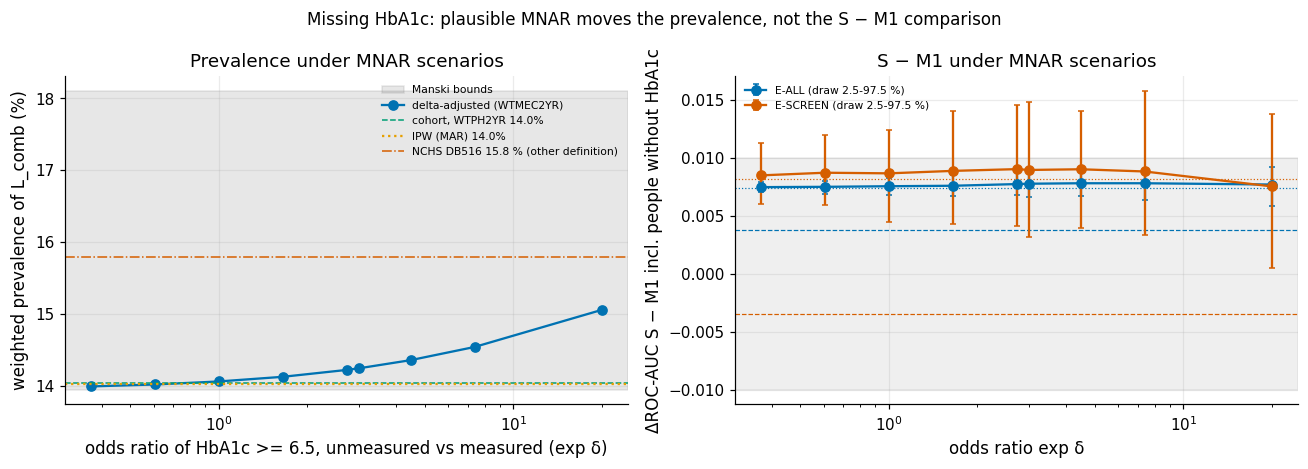

In [14]:
# Figure: prevalence (left) and delta AUC(S - M1) (right) across the delta scenarios; the x axis is
# exp(delta), the odds ratio of HbA1c >= 6.5 % for unmeasured versus measured people, on a log scale.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.axhspan(dprev.attrs["manski_low"] * 100, dprev.attrs["manski_high"] * 100, color=OI["grey"], alpha=0.18, label="Manski bounds")
ax.plot(dprev["odds_ratio"], dprev["prevalence"] * 100, "o-", color=OI["blue"], label="delta-adjusted (WTMEC2YR)")
ax.axhline(prev_tab.loc[0, "est"] * 100, color=OI["green"], ls="--", lw=1, label=f"cohort, WTPH2YR {prev_tab.loc[0, 'est']:.1%}")
ax.axhline(prev_tab.loc[2, "est"] * 100, color=OI["orange"], ls=":", lw=1.5, label=f"IPW (MAR) {prev_tab.loc[2, 'est']:.1%}")
ax.axhline(15.8, color=OI["vermillion"], ls="-.", lw=1, label="NCHS DB516 15.8 % (other definition)")
ax.set_xscale("log")
ax.set(xlabel="odds ratio of HbA1c >= 6.5, unmeasured vs measured (exp δ)", ylabel="weighted prevalence of L_comb (%)",
       title="Prevalence under MNAR scenarios")
ax.legend(fontsize=7)
ax = axes[1]
for pop, col in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
    d = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    ax.errorbar(np.exp(d["delta"]), d["diff"], yerr=[d["diff"] - d["diff_lo"], d["diff_hi"] - d["diff"]],
                fmt="o-", color=col, capsize=2, label=f"{pop} (draw 2.5-97.5 %)")
    for _, r in dauc[(dauc["pop"] == pop) & (dauc["scenario"] != "delta")].iterrows():
        # Manski bounds as horizontal lines: dotted = all undetermined negative, dashed = all undetermined
        # positive.
        ax.axhline(r["diff"], color=col, lw=0.8, ls=":" if "negative" in r["scenario"] else "--")
ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
ax.set_xscale("log")
ax.set(xlabel="odds ratio exp δ", ylabel="ΔROC-AUC S − M1 incl. people without HbA1c", title="S − M1 under MNAR scenarios")
ax.legend(fontsize=7)
fig.suptitle("Missing HbA1c: plausible MNAR moves the prevalence, not the S − M1 comparison", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_mnar_delta", caption="Left: weighted prevalence of L_comb in examined non-pregnant adults when the people without HbA1c "
              "(who did not report diabetes) have exp(δ) times the MAR odds of HbA1c >= 6.5; grey = Manski bounds; lines = WTPH2YR cohort "
              "estimate, IPW estimate and the DB516 figure (different definition, see section 8). Right: ΔROC-AUC (S − M1) when those "
              "people are added to E-ALL / E-SCREEN with labels drawn under δ (dotted / dashed = Manski all-negative / all-positive).")
plt.show()
S9["mnar"] = dict(n_examined=int(len(ex)), n_missing=int(miss.sum()), n_missing_self=int(miss_self.sum()),
                  ipw_range=[float(coh["ipw"].min()), float(coh["ipw"].max())], prevalence=prev_tab.round(5).to_dict("records"),
                  ipw_dauc=ipw_tab.round(5).to_dict("records"), delta_prevalence=dprev.round(5).to_dict("records"),
                  manski=[dprev.attrs["manski_low"], dprev.attrs["manski_high"]], tipping_delta_db516=tip,
                  delta_auc=dauc.round(5).to_dict("records"))

**So what.** This closes DR-S3-04 and DR-S5-08. **MAR:** IPW changes the weighted prevalence by about a tenth of a
point – as much as the WTPH2YR non-response adjustment already absorbs – and moves ΔAUC(S − M1) by less than 0.001.
**MNAR:** even at many-fold odds among the unmeasured the prevalence stays inside the Manski band; 4–5 % missingness
cannot lift it to DB516's 15.8 % (tipping point printed), so that gap is a *definition* gap (§9.8.2). **Model
comparison:** labels drawn under any δ from −1 to 3 shift ΔAUC(S − M1) by about 0.001; only the Manski "all
positive" extreme moves it noticeably, still inside ±0.01.

## 8 External validity
### 8.1 V1: NCHS Data Brief 516
**Why.** An external anchor tests the whole data path (loading, XPT repair, sentinels, weights, jackknife) against a
number we did not produce. §4 reproduced 27 published estimates of NCHS Data Brief 516; that replication is cited,
not re-run.

27 published estimates; max |ours - NCHS| = 0.044 pp; our KG interval matches the published one (to 0.1 pp) in 24/27; intervals overlap in 27/27
headline: total 15.79 % (NCHS 15.8), diagnosed 11.30 % (11.3), undiagnosed 4.49 % (4.5); n = 2,938


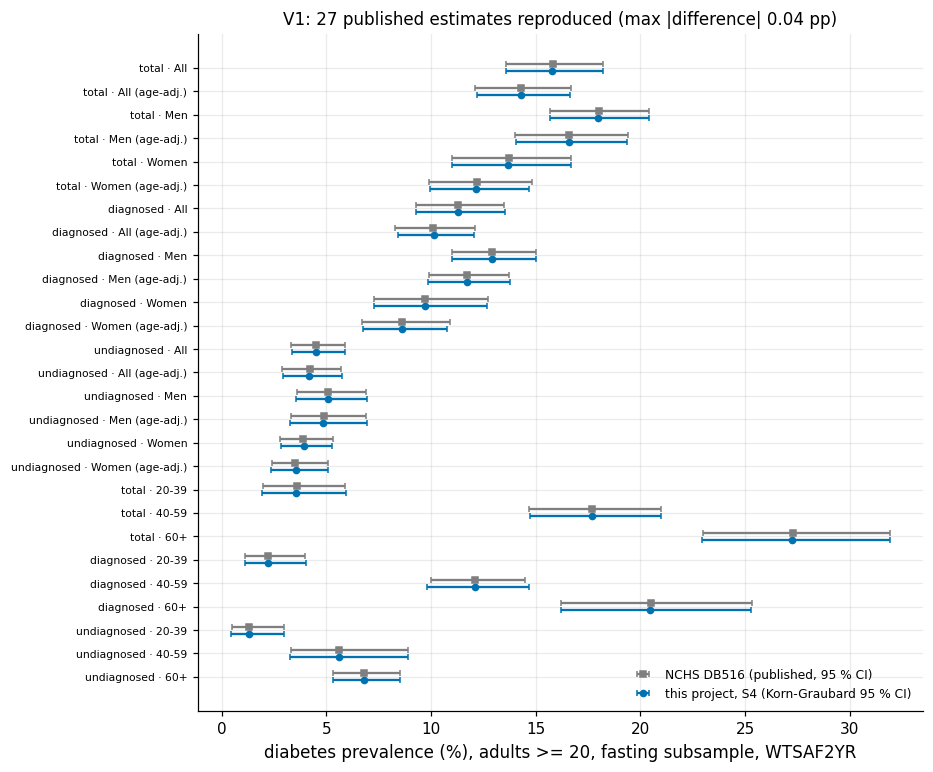

In [15]:
# External check V1: display the stored replication of the published NCHS Data Brief 516 estimates. Reads
# results/S4/db516_replication.csv (not recomputed here); asserts the three headline prevalences.
db = pd.read_csv(C.RESULTS_DIR / "S4" / "db516_replication.csv")
S4m = R.load_section("S4")["db516"]
db["label"] = db["measure"] + " · " + db["group"] + np.where(db["kind"] == "age-adj", " (age-adj.)", "")
print(f"{len(db)} published estimates; max |ours - NCHS| = {db['diff_pp'].abs().max():.3f} pp; "
      f"our KG interval matches the published one (to 0.1 pp) in {int(db['kg_matches_nchs_ci'].sum())}/{len(db)}; "
      f"intervals overlap in {int(db['ci_overlap'].sum())}/{len(db)}")
print(f"headline: total {S4m['total']:.2f} % (NCHS 15.8), diagnosed {S4m['diagnosed']:.2f} % (11.3), undiagnosed {S4m['undiagnosed']:.2f} % (4.5); n = {S4m['n']:,}")
# Published headline values (total 15.8 %, diagnosed 11.3 %, undiagnosed 4.5 %); 0.05 pp is half the rounding
# unit of the published figures.
assert abs(S4m["total"] - 15.8) < 0.05 and abs(S4m["diagnosed"] - 11.3) < 0.05 and abs(S4m["undiagnosed"] - 4.5) < 0.05

# Forest plot: the published NCHS interval (grey) beside our Korn-Graubard interval (blue) for each estimate.
fig, ax = plt.subplots(figsize=(8.5, 8))
# Two series per row, offset by -0.15 / +0.15 so that the two intervals do not overlap.
yy_ = np.arange(len(db))
ax.errorbar(db["nchs"], yy_ - 0.15, xerr=[db["nchs"] - db["nchs_low"], db["nchs_high"] - db["nchs"]], fmt="s", color=OI["grey"],
            capsize=2, ms=4, label="NCHS DB516 (published, 95 % CI)")
ax.errorbar(db["est"], yy_ + 0.15, xerr=[db["est"] - db["kg_low"], db["kg_high"] - db["est"]], fmt="o", color=OI["blue"],
            capsize=2, ms=4, label="this project, S4 (Korn-Graubard 95 % CI)")
ax.set_yticks(yy_, db["label"], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("diabetes prevalence (%), adults >= 20, fasting subsample, WTSAF2YR")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"V1: 27 published estimates reproduced (max |difference| {db['diff_pp'].abs().max():.2f} pp)", fontsize=11)
plots.savefig(fig, "S9_db516_forest", caption="F9-4. NCHS Data Brief 516 prevalence estimates (grey, published) and the S4 replication (blue, delete-one-PSU "
              "jackknife with Korn-Graubard intervals) for total, diagnosed and undiagnosed diabetes by sex and age, crude and age-adjusted. "
              "Source: results/S4/db516_replication.csv (not re-run in S9).")
plt.show()

**So what.** Every published estimate is reproduced to within 0.05 percentage points and every pair of intervals
overlaps: the data path is externally validated.

### 8.2 V2: why our prevalence is 14.0 % and not 15.8 %
**Why.** `L_comb` has a weighted prevalence of 14.0 % (WTPH2YR), below DB516's 15.8 %. The pre-registered explanation –
no fasting-glucose criterion, and the HbA1c sample instead of the fasting subsample – is decomposed with jackknife
intervals: (A) cohort, WTPH2YR → (B) fasting subsample, WTSAF2YR (sample effect) → (C) DB516 definition with fasting
glucose ≥ 126 mg/dL (definition effect).

In [16]:
# V2: split the gap between our prevalence of L_comb and the NCHS figure into a sample effect (HbA1c cohort ->
# fasting subsample) and a definition effect (adds fasting glucose >= 126 mg/dL). Intervals come from
# replicate weights (delete-one-PSU jackknife). Writes results/S9/v2_prevalence_gap.csv.
cohort_all = ctx.clean.copy()
# Mask of the fasting subsample, the only rows where the fasting-glucose label SL5 is defined.
fm = L.fasting_mask(cohort_all).to_numpy()
sl_all = L.sensitivity_labels(cohort_all)
# yA = L_comb; yC = SL5, the label with the NCHS fasting-glucose criterion (undefined outside the subsample,
# set to 0 here and masked out below).
yA = cohort_all["L_comb"].to_numpy(float)
yC = sl_all["SL5"].fillna(0).to_numpy(float)
# Replicate weights and jackknife factors for the two weight variables; the fasting weight is zeroed outside
# the subsample.
Wph, fac = sv.replicate_weights(cohort_all, C.WEIGHT_PHLEB)
Wsa, fac2 = sv.replicate_weights(cohort_all, cohort_all[C.WEIGHT_FASTING].fillna(0).to_numpy() * fm)
# Both weights share the survey design, so their jackknife factors must be identical.
assert np.allclose(fac, fac2)

# Weighted prevalence of y among the rows in mask m (all rows if None).
def _prev(y_, w_, m_=None):
    m_ = np.ones(len(y_), bool) if m_ is None else m_
    return (w_[m_] * y_[m_]).sum() / w_[m_].sum()

# A = cohort (WTPH2YR), B = fasting subsample with the same label, C = fasting subsample with the NCHS-style
# label. Returns [A, B, C, B - A, C - B, C - A].
def _abc(wph, wsa):
    a = _prev(yA, wph)
    b = _prev(yA, wsa, fm)
    c = _prev(yC, wsa, fm)
    return np.array([a, b, c, b - a, c - b, c - a])

w_ph = np.nan_to_num(cohort_all[C.WEIGHT_PHLEB].to_numpy(float))
w_sa = np.nan_to_num(cohort_all[C.WEIGHT_FASTING].to_numpy(float)) * fm
est_ = _abc(w_ph, w_sa)
# Recompute all quantities under each set of replicate weights.
reps_ = np.array([_abc(Wph[:, r], Wsa[:, r]) for r in range(Wph.shape[1])])
# Jackknife variance = sum over replicates of factor * (replicate estimate - full estimate)^2.
se_ = np.sqrt(np.tensordot(fac, (reps_ - est_) ** 2, axes=(0, 0)))
# t quantile with the design degrees of freedom (PSUs - strata) for the 95 % intervals.
tcrit = stats.t.ppf(0.975, sv.design_df(cohort_all))
v2 = pd.DataFrame({"quantity": ["A L_comb, cohort, WTPH2YR", "B L_comb, fasting subsample, WTSAF2YR",
                                "C DB516 definition (+ FPG >= 126), fasting subsample", "sample effect B - A",
                                "definition effect C - B", "total C - A"],
                   "est_pct": est_ * 100, "ci_low": (est_ - tcrit * se_) * 100, "ci_high": (est_ + tcrit * se_) * 100})
# People who are positive only through fasting glucose (SL5 = 1 but L_comb = 0).
fpg_only = int(((sl_all["SL5"] == 1) & (cohort_all["L_comb"] == 0)).sum())
v2.to_csv(OUT / "v2_prevalence_gap.csv", index=False)
show(v2, 2)
print(f"fasting subsample n = {int(fm.sum()):,}; people positive only through fasting glucose: {fpg_only}")
# A must reproduce the 14.0 % of §1 (0.15 pp tolerance) and C the published total of §9.8.1 (0.01 pp).
assert abs(est_[0] - 0.140) < 0.0015 and abs(est_[2] * 100 - S4m["total"]) < 0.01

quantity,est_pct,ci_low,ci_high
"A L_comb, cohort, WTPH2YR",14.04,12.44,15.63
"B L_comb, fasting subsample, WTSAF2YR",13.86,11.65,16.08
"C DB516 definition (+ FPG >= 126), fasting subsample",15.79,13.53,18.04
sample effect B - A,-0.17,-1.66,1.32
definition effect C - B,1.92,1.37,2.48
total C - A,1.75,0.24,3.26


fasting subsample n = 2,938; people positive only through fasting glucose: 70


**So what.** The gap is almost entirely a **definition** effect: the sample effect is small, while adding the
fasting-glucose criterion lifts the prevalence to the DB516 value. 14.0 % is not a failed replication but a narrower
label that misses people whose only abnormal test is fasting glucose – why SL5 is a sensitivity label (§9.4).

### 8.3 ADA-lite vs Bang et al. 2009 (qualitative)
**Why.** The published ADA test is only a qualitative yardstick: ADA-lite lacks two of seven items, our outcome is
HbA1c-based and the population is 2021–23. Verified from the Bang et al. (2009) abstract: cut-off ≥ 5, sensitivity
79 %, specificity 67 %; circulating AUC values are not verified and not used.

In [17]:
# ADA-lite on the training-part E-SCREEN rows: sensitivity, specificity and share flagged at point cut-offs 3,
# 4 and 5, set beside the published figures of Bang et al. 2009 (qualitative only). Reads the baseline AUC
# stored by §7.
ada_tr = P.ada_lite_items(ctx.cl)
# ADA-lite point score of the E-SCREEN rows only.
sc_esc = ada_tr["ada_score"].to_numpy()[ctx.esc]
ye = ctx.y_esc[ctx.esc]
ada_rows = []
for cut in (3, 4, 5):
    # Flag everyone at or above the cut-off; sensitivity among positives, specificity among negatives.
    call = sc_esc >= cut
    ada_rows.append(dict(cutoff=f">= {cut}", sensitivity=call[ye == 1].mean(), specificity=(~call[ye == 0]).mean(),
                         share_flagged=call.mean()))
ada_tab = pd.DataFrame(ada_rows)
# AUC of the same score as stored by §7 (not recomputed here).
bl = S7m["baselines"]["BL-ADAlite (points)"]
print(f"ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC {bl['escr_auc']:.3f} "
      f"[{bl['lo']:.3f}, {bl['hi']:.3f}], recall at specificity 0.80 {bl['escr_recall_spec80']:.3f} (S7)")
show(ada_tab, 3)
print("Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified")
S9["external"] = dict(db516=dict(n_estimates=len(db), max_abs_diff_pp=float(db["diff_pp"].abs().max()),
                                 kg_matches=int(db["kg_matches_nchs_ci"].sum()), ci_overlap=int(db["ci_overlap"].sum())),
                      v2=v2.round(4).to_dict("records"), fpg_only_positives=fpg_only,
                      ada_lite=dict(escr_auc=bl["escr_auc"], lo=bl["lo"], hi=bl["hi"], cutoffs=ada_tab.round(4).to_dict("records"),
                                    bang_2009_abstract="cut-off >= 5: sensitivity 0.79, specificity 0.67; AUC unverified"))

ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC 0.726 [0.681, 0.764], recall at specificity 0.80 0.244 (S7)


cutoff,sensitivity,specificity,share_flagged
>= 3,0.961,0.271,0.736
>= 4,0.835,0.444,0.565
>= 5,0.701,0.622,0.388


Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified


**So what.** At cut-off ≥ 5 ADA-lite reaches about 0.70 sensitivity at 0.62 specificity, below Bang's 0.79 / 0.67, as
expected with two items missing. It is a fair but conservative comparator, so S's §7 margin over it is likely
overstated (limitation L06).

## 9 Leak hunt
**Why.** The permutation test cannot see feature leakage, and the availability rule was applied from the
specification, not from the data. The leak hunt asks the data whether an *admissible* feature behaves like a disguised
label. Pre-registered triggers (M1 and S; age exempt): E-ALL AUC > 0.90; a single admissible feature with AUC > 0.75;
permutation failure; unstable coefficients. Exit: all top-10 features of S pass the availability proof and the
permutation test passes; at most two rounds. The non-admissible M0 columns are scanned too, to show that the scans
*can* find leakage.

In [18]:
# Leak hunt, single-feature scan: score every column of the naive M0 frame (plus the derived S columns) with a
# univariate AUC and flag admissible features above the trigger. Writes
# results/S9/leak_single_feature_auc.csv.
spec_v = P._spec_by_var()
# Columns that the variable specification admits at Tier 1 and at Tier 2.
adm1, adm2 = set(P.admissible_columns(1)), set(P.admissible_columns(2))
cats = set(P.categorical_columns())
# scan frame: per-variable-clean values of every M0 column + the derived S columns (BP means, weekly activity minutes)
raw_cols = [c for c in P.raw_feature_frame(ctx.raw_tr, 2).columns]
scan_df = ctx.cl[[c for c in raw_cols if c in ctx.cl.columns]].copy()
for c in ("bp_sys_mean", "bp_dia_mean", "pulse_mean", "pa_mod_min_wk", "pa_vig_min_wk"):
    scan_df[c] = pre_frame[c].to_numpy()

# Admissibility of a column; a derived column inherits the status of its source variables (all must be
# admissible).
def status(v):
    src = RB.DERIVED_SOURCES.get(v, (v,))
    if all(s in adm1 for s in src):
        return "admissible T1"
    if all(s in adm2 for s in src):
        return "admissible T2"
    return f"not admissible ({spec_v['role'].get(src[0], 'derived')})"

# Univariate AUC on E-ALL. Numeric columns by rank; categorical ones by out-of-fold target encoding, so the
# encoding never sees the labels it is scored on. auc_oriented = max(AUC, 1 - AUC): a strongly inverse feature
# counts as well.
single = RB.single_feature_scan(scan_df, ctx.y, ctx.folds, cat_cols=cats)
# The same scan on E-SCREEN only, to see whether a feature's signal comes from known diagnoses.
single_e = RB.single_feature_scan(scan_df, ctx.y_esc, ctx.folds, cat_cols=cats, mask=ctx.esc)
single = single.merge(single_e[["variable", "auc_oriented"]].rename(columns={"auc_oriented": "auc_escreen"}), on="variable")
single["status"] = single["variable"].map(status)
single["admissible"] = single["status"].str.startswith("admissible")
# Trigger: admissible, above the 0.75 threshold and not age (age is exempt, a legitimate strong predictor).
single["trigger"] = single["admissible"] & (single["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC) & ~single["variable"].isin(RB.AGE_EXEMPT)
single.to_csv(OUT / "leak_single_feature_auc.csv", index=False)
show(single.head(25)[["variable", "status", "kind", "coverage", "auc_oriented", "auc_escreen", "trigger"]], 3)
print(f"admissible features above {RB.L3_SINGLE_FEATURE_AUC} (age exempt): {single.loc[single['trigger'], 'variable'].tolist()}")
print(f"non-admissible M0 columns above {RB.L3_SINGLE_FEATURE_AUC}: "
      f"{single.loc[~single['admissible'] & (single['auc_oriented'] > RB.L3_SINGLE_FEATURE_AUC), 'variable'].tolist()}")
# The table is sorted by AUC, so the first admissible row is the strongest admissible feature.
best_adm = single[single["admissible"]].iloc[0]
print(f"strongest admissible feature: {best_adm['variable']} AUC {best_adm['auc_oriented']:.3f}")

variable,status,kind,coverage,auc_oriented,auc_escreen,trigger
DIQ160,not admissible (leak),categorical (OOF target encoding),1.000,0.930,0.657,False
DIQ070,not admissible (leak),categorical (OOF target encoding),1.000,0.920,0.653,False
DIQ050,not admissible (leak),categorical (OOF target encoding),1.000,0.917,0.505,False
DIQ180,not admissible (leak),categorical (OOF target encoding),1.000,0.912,0.586,False
LBXGLU,not admissible (leak),numeric,0.555,0.895,0.934,False
BMXWAIST,admissible T1,numeric,0.955,0.706,0.734,False
BPQ020,admissible T1,categorical (OOF target encoding),1.000,0.671,0.580,False
LBDLDL,not admissible (side),numeric,0.527,0.668,0.517,False
BMXBMI,admissible T1,numeric,0.986,0.668,0.708,False
RIDAGEYR,admissible T1,numeric,1.000,0.666,0.634,False


admissible features above 0.75 (age exempt): []
non-admissible M0 columns above 0.75: ['DIQ160', 'DIQ070', 'DIQ050', 'DIQ180', 'LBXGLU']
strongest admissible feature: BMXWAIST AUC 0.706


In [19]:
# Leak hunt, missing-indicator scan: AUC of 'is missing' for every column with partial missingness. A skip
# pattern that tracks the label would show up here. Writes results/S9/leak_missing_indicator_auc.csv.
miss_scan = RB.missing_indicator_scan(scan_df, ctx.y)
miss_scan["status"] = miss_scan["variable"].map(status)
miss_scan["admissible"] = miss_scan["status"].str.startswith("admissible")
miss_scan["trigger"] = miss_scan["admissible"] & (miss_scan["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC)
miss_scan.to_csv(OUT / "leak_missing_indicator_auc.csv", index=False)
show(miss_scan.head(12)[["variable", "status", "n_missing", "prev_if_missing", "prev_if_present", "auc_oriented", "trigger"]], 3)
print(f"admissible is_missing indicators above {RB.L3_SINGLE_FEATURE_AUC}: {miss_scan.loc[miss_scan['trigger'], 'variable'].tolist()}; "
      f"largest admissible: {miss_scan[miss_scan['admissible']].iloc[0]['variable']} "
      f"{miss_scan[miss_scan['admissible']].iloc[0]['auc_oriented']:.3f}")

variable,status,n_missing,prev_if_missing,prev_if_present,auc_oriented,trigger
DIQ160,not admissible (leak),831,0.819,0.026,0.919,False
DIQ050,not admissible (leak),3934,0.032,1.000,0.918,False
DID040,not admissible (leak),3945,0.035,1.000,0.911,False
DIQ180,not admissible (leak),793,0.822,0.033,0.901,False
DIQ070,not admissible (leak),3202,0.018,0.520,0.875,False
DID060,not admissible (leak),4376,0.130,1.000,0.634,False
DIQ060U,not admissible (leak),4377,0.130,1.000,0.633,False
PAD820,admissible T1,2584,0.228,0.094,0.617,False
PAD810U,admissible T1,2578,0.228,0.095,0.616,False
PAD800,admissible T1,974,0.271,0.142,0.577,False


admissible is_missing indicators above 0.75: []; largest admissible: PAD820 0.617


In [20]:
# Leak hunt, depth-1 trees: a single-split tree per arm shows which variable the arm relies on most. Writes
# results/S9/leak_depth1_tree.csv; the root of M1 and S must be an admissible variable.
d1 = {}
for arm in ("M0", "M1", "S"):
    sp = Spec(arm, model="tree", depth=1)
    # Root variable of every fold fit; fold -1 is the fit on the whole training part ('__none__' tracks no
    # feature).
    tf = RB.tree_features_used(ctx, sp, ctx.folds, "__none__")
    oof1 = RB.run_many(ctx, {"t": sp}, n_jobs=N_JOBS, cache=RUNS)["t"]
    d1[arm] = dict(root_full_fit=tf.loc[tf["fold"] == -1, "root"].iloc[0], roots_in_folds=tf.loc[tf["fold"] >= 0, "root"].value_counts().to_dict(),
                   oof_auc_eall=roc_auc_score(ctx.y, ek.mean_oof(oof1, ctx.n)),
                   oof_auc_escreen=roc_auc_score(ctx.y_esc[ctx.esc], ek.mean_oof(oof1, ctx.n)[ctx.esc]))
d1_tab = pd.DataFrame(d1).T
# Map the root column back to its source variable, then classify it as admissible or not.
d1_tab["root_variable"] = d1_tab["root_full_fit"].map(RB.base_variable)
d1_tab["root_status"] = d1_tab["root_variable"].map(status)
d1_tab.to_csv(OUT / "leak_depth1_tree.csv")
display(d1_tab)

,root_full_fit,roots_in_folds,oof_auc_eall,oof_auc_escreen,root_variable,root_status
M0,DIQ070_2.0,{'DIQ070_2.0': 25},0.796572,0.564676,DIQ070,not admissible (leak)
M1,BPQ020_2.0,{'BPQ020_2.0': 25},0.663589,0.570412,BPQ020,admissible T1
S,BPQ020_1.0,"{'BPQ020_2.0': 19, 'BPQ020_1.0': 6}",0.667057,0.578739,BPQ020,admissible T1


**So what (scans).** The scans work – among the non-admissible M0 columns they flag treatment and diagnosis-history
items far above 0.75 – and find nothing among the admissible ones: the strongest admissible feature stays below
0.75, admissible `is_missing` indicators are close to 0.5, and the depth-1 trees of M1 and S split on admissible items.

In [21]:
# Leak hunt, importance and care-contact checks: availability proof for the ten most important features of S
# (each tier), effect of removing the care-contact items, and stability of the coefficients. Writes
# results/S9/leak_top10_availability.csv.
pipe_S = {t: RB.fit_full(ctx, Spec("S", tier=t)) for t in (1, 2)}
# Importance = standard deviation of each variable's contribution to the linear predictor (`sd_contribution`).
imp = {t: RB.contribution_importance(pipe_S[t], ctx.X[t]) for t in (1, 2)}
proof = []
for t in (1, 2):
    top = imp[t].head(10).copy()
    # For each top variable: its sources, the instrument that measures it, admissibility and care-contact
    # flag, and a PASS / FAIL verdict on whether it is available at the screening moment.
    pf = RB.availability_proof(top["variable"], tier=t)
    proof.append(top.merge(pf, on="variable").assign(tier=t))
proof = pd.concat(proof, ignore_index=True)
proof.to_csv(OUT / "leak_top10_availability.csv", index=False)
show(proof[["tier", "variable", "sd_contribution", "sources", "instrument", "admissible", "care_contact", "verdict"]], 3)
top_pass = bool((proof["verdict"] == "PASS").all())
print(f"top-10 availability proof: {'all PASS' if top_pass else 'FAIL: ' + str(proof.loc[proof['verdict'] != 'PASS', 'variable'].tolist())}")

# Remove the care-contact items (BPQ020, BPQ080): T1-minus-care - S. Informative only; it does not trigger a
# leak-hunt round.
care = pair(Spec("T1-minus-care"), Spec("S"), tag="minus-care")
care_items = single.set_index("variable").loc[list(P.CARE_ITEMS), ["auc_oriented", "auc_escreen"]]
print("T1-minus-care - S: " + "; ".join(f"{r['pop']} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]" for r in care))
display("care-contact items, single-feature AUC (E-ALL vs E-SCREEN):"); print(care_items.round(3))

# Coefficient bootstrap of S taken from the noise-feature run (noise column removed).
cbS = NOISE_CB["S"].summary.drop(index="noise_n01")
# Unstable coefficient: interval excludes 0 but the sign flips in more than 10 % of the bootstrap refits.
unstable = cbS[(cbS["ci_excludes_0"]) & (cbS["sign_flip_rate"] > 0.10)]
print(f"coefficients of S whose CI excludes 0 but flip sign in > 10 % of {B_COEF9} refits: {len(unstable)}; "
      f"max flip rate among CI-excluding-0 coefficients {cbS.loc[cbS['ci_excludes_0'], 'sign_flip_rate'].max():.3f}")

tier,variable,sd_contribution,sources,instrument,admissible,care_contact,verdict
1,BMXHIP,0.815,BMXHIP,MEC body measures (tape / scale),T1,False,PASS
1,BMXBMI,0.741,BMXBMI,MEC body measures (tape / scale),T1,False,PASS
1,RIDAGEYR,0.699,RIDAGEYR,household interview (demographics),T1,False,PASS
1,pulse_mean,0.685,"BPXOPLS1,BPXOPLS2,BPXOPLS3",MEC oscillometric blood pressure,T1,False,PASS
1,BMXWAIST,0.633,BMXWAIST,MEC body measures (tape / scale),T1,False,PASS
1,bp_dia_mean,0.581,"BPXODI1,BPXODI2,BPXODI3",MEC oscillometric blood pressure,T1,False,PASS
1,bp_sys_mean,0.445,"BPXOSY1,BPXOSY2,BPXOSY3",MEC oscillometric blood pressure,T1,False,PASS
1,BPQ080,0.399,BPQ080,interview questionnaire (blood pressure & cholesterol),T1,True,PASS
1,BPQ020,0.352,BPQ020,interview questionnaire (blood pressure & cholesterol),T1,True,PASS
1,INDFMPIR,0.260,INDFMPIR,household interview (demographics),T1,False,PASS


top-10 availability proof: all PASS


T1-minus-care - S: E-ALL -0.0157 [-0.0221, -0.0093]; E-SCREEN +0.0192 [+0.0040, +0.0344]


'care-contact items, single-feature AUC (E-ALL vs E-SCREEN):'

          auc_oriented  auc_escreen
variable                           
BPQ020           0.671        0.580
BPQ080           0.657        0.547
coefficients of S whose CI excludes 0 but flip sign in > 10 % of 500 refits: 0; max flip rate among CI-excluding-0 coefficients 0.022


In [22]:
# Leak-hunt log: one row per pre-registered trigger with its value and whether it fired (triggered = True is a
# failed check and would start another round). Writes results/S9/leak_hunt_log.csv.
t1_auc = {a: S9["reference"]["E-ALL"]["auc_a" if a == "S" else "auc_b"] for a in ("S", "M1")}
log = pd.DataFrame([
    dict(check="T1 E-ALL AUC > 0.90 (M1, S)", value=f"M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}", triggered=max(t1_auc.values()) > RB.L3_T1_EALL_AUC),
    dict(check="admissible single feature AUC > 0.75 (age exempt)", value=f"max {single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT), 'auc_oriented'].max():.3f} "
         f"({single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT)].iloc[0]['variable']})", triggered=bool(single["trigger"].any())),
    dict(check="admissible is_missing indicator AUC > 0.75", value=f"max {miss_scan.loc[miss_scan['admissible'], 'auc_oriented'].max():.3f}",
         triggered=bool(miss_scan["trigger"].any())),
    dict(check="depth-1 tree root of M1 / S admissible", value=f"M1 {d1_tab.loc['M1', 'root_variable']}, S {d1_tab.loc['S', 'root_variable']}",
         triggered=not (d1_tab.loc[["M1", "S"], "root_status"].str.startswith("admissible").all())),
    dict(check="permutation null mean in [0.495, 0.505] (M1, S)", value=", ".join(f"{a} {d['null_mean']:.4f}" for a, d in PERM.items()),
         triggered=not perm_tab["in_band"].all()),
    dict(check="coefficient instability (CI excludes 0 and > 10 % sign flips, S)", value=f"{len(unstable)} coefficients", triggered=len(unstable) > 0),
    dict(check="top-10 features of S (T1, T2) pass the availability proof", value=f"{int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS",
         triggered=not top_pass),
    dict(check="T1-minus-care vs S (informative, no trigger)", value="; ".join(f"{r['pop']} {r['est']:+.3f}" for r in care), triggered=False),
])
# Action column: any fired trigger sends the work back to re-examine the feature.
log["action"] = np.where(log["triggered"], "leak-hunt round: re-examine feature, back to §6/§7", "none")
log.to_csv(OUT / "leak_hunt_log.csv", index=False)
show(log)
L3_TRIGGERED = bool(log["triggered"].any())
print(f"leak hunt triggered: {L3_TRIGGERED} -> {'rounds needed' if L3_TRIGGERED else 'exit condition met in round 0 (no re-run of §7)'}")
S9["leak_hunt"] = dict(triggered=L3_TRIGGERED, log=log.to_dict("records"), top10=proof[["tier", "variable", "sd_contribution", "verdict"]].round(5).to_dict("records"),
                       depth1=d1_tab[["root_full_fit", "root_variable", "oof_auc_eall", "oof_auc_escreen"]].to_dict("index"),
                       strongest_admissible=dict(variable=best_adm["variable"], auc=best_adm["auc_oriented"]),
                       minus_care={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in care})

check,value,triggered,action
"T1 E-ALL AUC > 0.90 (M1, S)","M1 0.828, S 0.836",False,none
admissible single feature AUC > 0.75 (age exempt),max 0.706 (BMXWAIST),False,none
admissible is_missing indicator AUC > 0.75,max 0.617,False,none
depth-1 tree root of M1 / S admissible,"M1 BPQ020, S BPQ020",False,none
"permutation null mean in [0.495, 0.505] (M1, S)","M1 0.5015, S 0.5014",False,none
"coefficient instability (CI excludes 0 and > 10 % sign flips, S)",0 coefficients,False,none
"top-10 features of S (T1, T2) pass the availability proof",20/20 PASS,False,none
"T1-minus-care vs S (informative, no trigger)",E-ALL -0.016; E-SCREEN +0.019,False,none


leak hunt triggered: False -> exit condition met in round 0 (no re-run of §7)


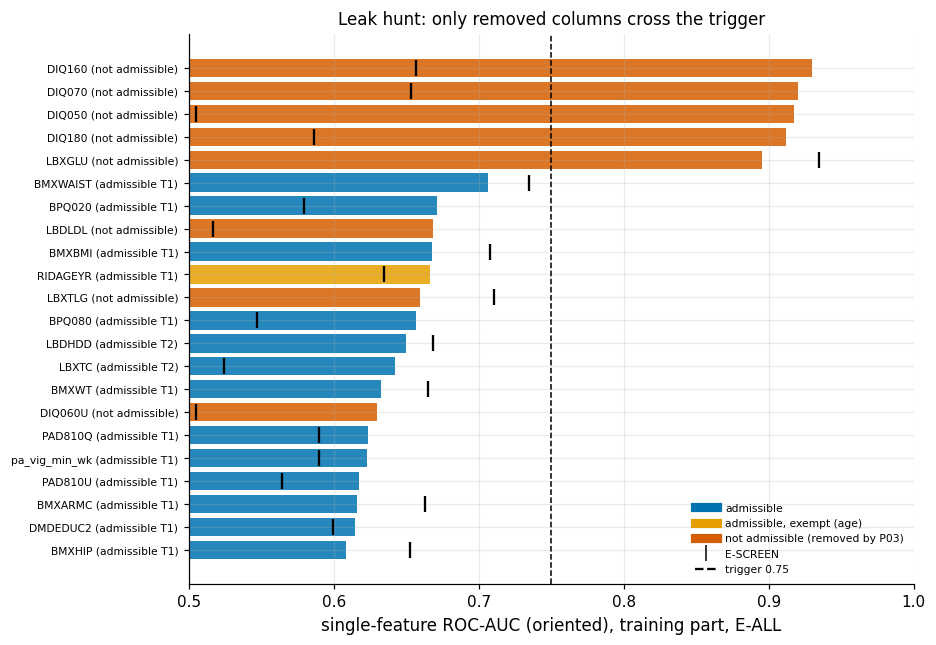

In [23]:
# Figure: the 22 strongest single-feature AUCs; reversed so that the strongest bar is drawn at the top.
top_scan = single.head(22).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
# Red = removed by the availability rule, orange = admissible but exempt (age), blue = admissible.
cols_ = [OI["vermillion"] if not a else (OI["orange"] if v in RB.AGE_EXEMPT else OI["blue"]) for a, v in zip(top_scan["admissible"], top_scan["variable"])]
ax.barh(range(len(top_scan)), top_scan["auc_oriented"], color=cols_, alpha=0.85)
ax.scatter(top_scan["auc_escreen"], range(len(top_scan)), marker="|", s=120, color="k", label="same feature on E-SCREEN", zorder=3)
ax.axvline(RB.L3_SINGLE_FEATURE_AUC, color="k", ls="--", lw=1, label="L3 trigger 0.75")
ax.set_yticks(range(len(top_scan)), [f"{v} ({s.split(' (')[0]})" for v, s in zip(top_scan["variable"], top_scan["status"])], fontsize=7)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("single-feature ROC-AUC (oriented), training part, E-ALL")
ax.legend(handles=[Line2D([], [], color=OI["blue"], lw=6, label="admissible"), Line2D([], [], color=OI["orange"], lw=6, label="admissible, exempt (age)"),
                   Line2D([], [], color=OI["vermillion"], lw=6, label="not admissible (removed by P03)"),
                   Line2D([], [], color="k", marker="|", ls="", ms=10, label="E-SCREEN"),
                   Line2D([], [], color="k", ls="--", label="trigger 0.75")], fontsize=7, loc="lower right")
ax.set_title("Leak hunt: only removed columns cross the trigger", fontsize=11)
plots.savefig(fig, "S9_single_feature_auc", caption="F9-5. Univariate ROC-AUC of the 22 strongest columns of the naive M0 frame (plus derived S columns), "
              "training part, E-ALL (bars) and E-SCREEN (ticks). Categorical items use out-of-fold target encoding. Red = removed by the "
              "availability rule; blue = admissible; dashed = L3 trigger 0.75 (age exempt).")
plt.show()

**So what.** The leak hunt is **not triggered**: the admissible arms stay far below 0.90, no admissible feature except
the exempt age exceeds 0.75, and each of the ten most important features of S (Tier 1 and 2) passes the point-of-care
availability proof. The exit condition is met in round 0, so §7 is not re-run. One caveat survives: "told high blood
pressure" and "told high cholesterol" are **care-contact traces** – admissible, but more informative for people
already in care; removing them costs AUC on E-ALL but not on E-SCREEN. That is the mechanism of H2c, not leakage.

## 10 Pre-hold-out summary
**Why.** Before the freeze, every robustness result for S − M1 is put on one scale, so that the robustness grade of the
claim (§10.7) can be read off one table and one figure.

check,pop,est_min,est_max,lo,hi,verdicts
reference (stored folds),E-ALL,0.0079,0.0079,0.0000,0.0158,inconclusive
10 CV seeds,E-ALL,0.0058,0.0078,-0.0018,0.0155,inconclusive 10
16 sensitivity specs,E-ALL,-0.0061,0.0116,-0.0233,0.0230,inconclusive 16
60-spec curve,E-ALL,0.0048,0.0182,-0.0046,0.0266,inconclusive 60
strata x PSU grouped CV,E-ALL,0.0055,0.0055,-0.0001,0.0118,inconclusive 1
IPW (evaluation; fit + evaluation),E-ALL,0.0072,0.0079,-0.0009,0.0158,inconclusive 2
MNAR delta -1 to 3 (draw means),E-ALL,0.0075,0.0078,0.0059,0.0092,n/a (no CI)
reference (stored folds),E-SCREEN,0.0085,0.0085,-0.0081,0.0236,inconclusive
10 CV seeds,E-SCREEN,0.0062,0.0104,-0.0090,0.0248,inconclusive 10
16 sensitivity specs,E-SCREEN,-0.0119,0.0204,-0.0389,0.0407,inconclusive 16


E-ALL: 89 alternative comparisons with a CI -> verdicts {'inconclusive': 89}
E-SCREEN: 89 alternative comparisons with a CI -> verdicts {'inconclusive': 89}


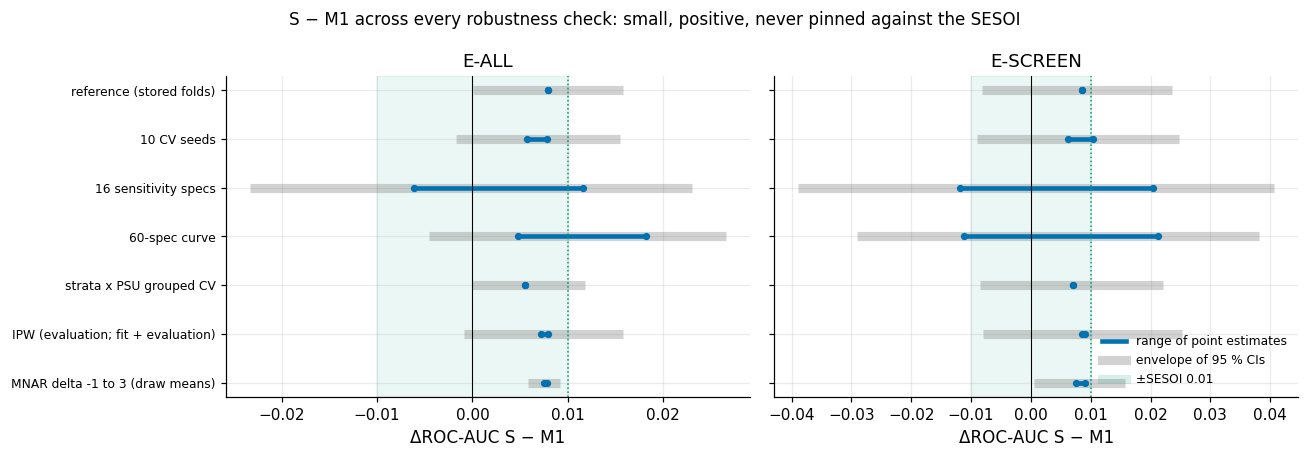

In [24]:
# Pre-hold-out summary: put every robustness family on one scale (range of the S - M1 point estimates and the
# envelope of the intervals). Reads the tables above; writes results/S9/robustness_summary.csv. Returns (min
# estimate, max estimate, lowest lower bound, highest upper bound, verdict counts) of one family.
def _rng(d, pop):
    x = d[d["pop"] == pop]
    return x["est"].min(), x["est"].max(), x["lo"].min(), x["hi"].max(), ", ".join(f"{k} {v}" for k, v in x["h2b"].value_counts().items())

summ = []
for pop in ("E-ALL", "E-SCREEN"):
    r0 = S9["reference"][pop]
    summ.append(dict(check="reference (stored folds)", pop=pop, est_min=r0["est"], est_max=r0["est"], lo=r0["lo"], hi=r0["hi"], verdicts=r0["h2b"]))
    for nm, d in ((f"{len(SEED_FOLDS)} CV seeds", seeds), (f"{len(SENS)} sensitivity specs", sens[sens["spec"] != "reference (S7)"]),
                  (f"{len(grid)}-spec curve", curve), ("strata x PSU grouped CV", gcv_tab[gcv_tab["folds"] != "stored stratified"]),
                  ("IPW (evaluation; fit + evaluation)", ipw_tab)):
        a, b, lo, hi, v = _rng(d, pop)
        summ.append(dict(check=nm, pop=pop, est_min=a, est_max=b, lo=lo, hi=hi, verdicts=v))
    dd = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    summ.append(dict(check="MNAR delta -1 to 3 (draw means)", pop=pop, est_min=dd["diff"].min(), est_max=dd["diff"].max(),
                     lo=dd["diff_lo"].min(), hi=dd["diff_hi"].max(), verdicts="n/a (no CI)"))
summ = pd.DataFrame(summ)
summ.to_csv(OUT / "robustness_summary.csv", index=False)
show(summ, 4)
# All verdicts of the alternative comparisons that come with an interval (seeds, sensitivity, curve, grouped
# CV, IPW); the MNAR draws have no interval and are left out.
fam_v = {pop: pd.concat([seeds.loc[seeds["pop"] == pop, "h2b"], sens.loc[(sens["pop"] == pop) & (sens["spec"] != "reference (S7)"), "h2b"],
                         curve.loc[curve["pop"] == pop, "h2b"], gcv_tab.loc[(gcv_tab["pop"] == pop) & (gcv_tab["folds"] != "stored stratified"), "h2b"],
                         ipw_tab.loc[ipw_tab["pop"] == pop, "h2b"]]) for pop in ("E-ALL", "E-SCREEN")}
# True if every alternative comparison of a population is inconclusive.
all_incon = {pop: bool((v == "inconclusive").all()) for pop, v in fam_v.items()}
for pop, v in fam_v.items():
    print(f"{pop}: {len(v)} alternative comparisons with a CI -> verdicts {v.value_counts().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = summ[summ["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.plot([r["lo"], r["hi"]], [i, i], color=OI["grey"], lw=6, alpha=0.35, solid_capstyle="butt")
        ax.plot([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], lw=3)
        ax.scatter([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], s=14, zorder=3)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["green"], alpha=0.08)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(C.SESOI["roc_auc"], color=OI["green"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1")
axes[0].set_yticks(range(len(s)), s["check"], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], color=OI["blue"], lw=3, label="range of point estimates"),
                        Line2D([], [], color=OI["grey"], lw=6, alpha=0.35, label="envelope of 95 % CIs"),
                        Line2D([], [], color=OI["green"], lw=6, alpha=0.15, label="±SESOI 0.01")], fontsize=8, loc="lower right")
fig.suptitle("S − M1 across every robustness check: small, positive, never pinned against the SESOI", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_robustness_summary", caption="Range of ΔROC-AUC (S − M1) point estimates (blue) and envelope of the 95 % CIs (grey) for each "
              f"family of robustness checks: stored folds, {len(SEED_FOLDS)} CV seeds, {len(SENS)} one-at-a-time specifications, {len(grid)}-specification curve, "
              "strata x PSU grouped CV, inverse-probability weighting and MNAR delta adjustment; E-ALL left, E-SCREEN right.")
plt.show()
S9["summary"] = dict(table=summ.round(5).to_dict("records"), all_inconclusive=all_incon)

**So what – controls and stability (§9.2–§9.7).** The procedure is neither optimistic nor blind: permutation nulls
centre on 0.5, the noise column is ignored (interval covers 0, no tree split) and the AUC-0.60 control is recovered and
detected (only a few thousandths of AUC on top of age, adiposity and blood pressure). For S − M1 every check agrees:
ten seeds move the estimate only in the third decimal; all 60 curve specifications put S ahead, none clears or sits
inside ±0.01; PSU-grouped folds change the AUC of S by a few thousandths; IPW and MNAR leave it unchanged. On E-ALL
S leads by roughly 0.005–0.015 and, apart from the depth-4 tree (DR-S9-13), no interval falls below about −0.01. The
robust reading of H2b(a) is "**S is at least as good as M1 and probably slightly better, by an amount that cannot be
distinguished from 0.01**" – *robust verdict, imprecise effect*; on E-SCREEN intervals are about twice as wide.

In [25]:
# decision-register rows of §9 (written and listed in §9.13 Outputs)
# Build the §9 rows of the decision register from the numbers computed above (nothing is typed in by hand).
# The file itself is written in §9.13, and only in FINAL mode.
from datetime import date
today = date.today().isoformat()
# Format a comparison row as 'est [lo, hi]' with k decimals.
def _f(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}]"

pc = pos_tab.set_index(["arm", "pop"])
reg = pd.DataFrame([
    dict(dr_id="DR-S9-01", type="negative_control", finding="Label-permutation null centred on 0.5 for both admissible arms; tests procedural leakage only",
         evidence_ref="results/S9/permutation.csv; figures/S9_permutation_null.png",
         evidence_value=f"null mean M1 {PERM['M1']['null_mean']:.4f}, S {PERM['S']['null_mean']:.4f} ({C.N_PERM} permutations); p = {PERM['S']['p_value']:.3f}",
         decision="Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt", alternatives_rejected="sklearn permutation_test_score (no sample weights per fold, no fixed folds)",
         hyp_id="", status="decided", check_verdict="PASS", check_note="band [0.495, 0.505]", loop_ref="leak hunt §9.9"),
    dict(dr_id="DR-S9-02", type="negative_control", finding="An N(0,1) noise column is treated as noise",
         evidence_ref="results/S9/noise_feature.csv",
         evidence_value="; ".join(f"{r['arm']}: coef/SD {r['coef_per_sd']:+.3f} [{r['q_low']:+.3f}, {r['q_high']:+.3f}], dAUC {r['dAUC_eall']:+.4f}, depth-3 trees using it {r['tree3_uses']}/{r['n_trees']}" for _, r in noise_tab.iterrows()),
         decision="No overfitting to noise; depth cap 3 for the tree probe retained", alternatives_rejected="", hyp_id="", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-03", type="positive_control", finding="A synthetic feature with known AUC 0.60 is recovered and detected",
         evidence_ref="results/S9/positive_control.csv",
         evidence_value=f"z AUC {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}]; dAUC E-ALL M1 {pc.loc[('M1', 'E-ALL'), 'est']:+.4f} [{pc.loc[('M1', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('M1', 'E-ALL'), 'hi']:+.4f}], S {pc.loc[('S', 'E-ALL'), 'est']:+.4f} [{pc.loc[('S', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('S', 'E-ALL'), 'hi']:+.4f}]",
         decision="Procedure has power for weak real signals; negative controls are not passed by blindness", alternatives_rejected="",
         hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-04", type="seed_stability", finding="S - M1 verdict does not depend on the CV / bootstrap seed",
         evidence_ref="results/S9/seed_stability.csv; figures/S9_seed_stability.png",
         evidence_value=f"E-ALL est {seed_sum.loc['E-ALL', 'est_min']:+.4f} to {seed_sum.loc['E-ALL', 'est_max']:+.4f}; verdicts {seed_sum.loc['E-ALL', 'verdicts']}",
         decision="H2b(a) verdict graded seed-stable", alternatives_rejected="single seed", hyp_id="H2b", status="decided",
         check_verdict="PASS" if seed_stable else "FAIL", check_note="10 seeds via evalkit.derive_seed; hold-out fixed", loop_ref=""),
    dict(dr_id="DR-S9-05", type="sensitivity", finding="16 one-at-a-time analysis variations leave the E-ALL verdict of S - M1 unchanged",
         evidence_ref="results/S9/sensitivity_table.csv; figures/S9_sensitivity_forest.png",
         evidence_value=f"E-ALL same verdict {n_same}/{len(eall)}; est {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; no CI wholly below 0",
         decision="H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)",
         alternatives_rejected="reporting only the reference specification", hyp_id="H2b", status="decided",
         check_verdict="PASS" if n_same == len(eall) else "PARTIAL", check_note="E-SCREEN all inconclusive (wide CIs)", loop_ref=""),
    dict(dr_id="DR-S9-06", type="tuning", finding="Arm-specific tuning of C gives M0 and M1 the same C as S",
         evidence_ref="§9.4; results/S9/sensitivity_table.csv",
         evidence_value=f"own C: M0 {OWN_C['M0'][0]}, M1 {OWN_C['M1'][0]} (C0 {ctx.C0}); leak gate own C E-ALL {_f(gate_own[0])}",
         decision="Tuning C on S does not favour S across arms (M0, M1 and S pick the same C); 'same model for every arm' rule kept. "
                  "This tests arm fairness, not nesting: the tuning optimism of the un-nested C0 is bounded by the post-audit nested check (DR-S9-17)",
         alternatives_rejected="per-arm tuning as primary design",
         hyp_id="H2a;H2b", status="decided", check_verdict="PASS", check_note="closes the arm-fairness item of DR-S7-04; nesting: DR-S9-17", loop_ref="DR-S9-17"),
    dict(dr_id="DR-S9-07", type="sensitivity", finding="60-specification curve (label x weighting x C) agrees with the core table",
         evidence_ref="results/S9/specification_curve.csv; figures/S9_specification_curve.png",
         evidence_value=f"E-ALL est {cs.loc['E-ALL', 'est_min']:+.4f} to {cs.loc['E-ALL', 'est_max']:+.4f}, {cs.loc['E-ALL', 'share_positive']:.0%} positive, "
                        f"{cs.loc['E-ALL', 'share_ci_above_0']:.0%} CI above 0, {cs.loc['E-ALL', 'share_beyond_sesoi']:.0%} beyond SESOI",
         decision="Extension item; does not change the core table", alternatives_rejected="", hyp_id="H2b", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-08", type="sensitivity", finding="Survey-cluster folds (strata x PSU) do not inflate or change the comparison",
         evidence_ref="results/S9/grouped_cv.csv",
         evidence_value=f"{len(np.unique(groups))} clusters; AUC(S) grouped - stratified E-ALL {dS['E-ALL']:+.4f}; S - M1 grouped {_f(gcv[0], 4)}",
         decision="Stratified (non-grouped) folds kept as primary design", alternatives_rejected="grouped folds as primary (unbalanced E-SCREEN positives per fold)",
         hyp_id="H2b", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-09", type="missingness", finding="Missing HbA1c: MAR (IPW) and MNAR (delta) scenarios move prevalence little and S - M1 not at all",
         evidence_ref="results/S9/ipw.csv; results/S9/mnar_delta_prevalence.csv; results/S9/mnar_delta_auc.csv; figures/S9_mnar_delta.png",
         evidence_value=f"prevalence WTPH2YR {prev_tab.loc[0, 'est']:.2%}, MEC x IPW {prev_tab.loc[2, 'est']:.2%}; delta OR 0.37-20: "
                        f"{dprev['prevalence'].min():.2%}-{dprev['prevalence'].max():.2%}; Manski [{dprev.attrs['manski_low']:.2%}, {dprev.attrs['manski_high']:.2%}]; "
                        f"OR needed for 15.8 %: {np.exp(tip):.0f}; S - M1 E-ALL under delta {dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].min():+.4f} to "
                        f"{dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].max():+.4f}",
         decision="Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions",
         alternatives_rejected="imputing HbA1c (would impute the label)", hyp_id="", status="decided", check_verdict="PASS",
         check_note="closes DR-S3-04 and DR-S5-08", loop_ref="DR-S3-04;DR-S5-08"),
    dict(dr_id="DR-S9-10", type="validation", finding="V1 DB516 replication holds; V2 gap 14.0 % vs 15.8 % is a label-definition gap",
         evidence_ref="results/S4/db516_replication.csv; results/S9/v2_prevalence_gap.csv; figures/S9_db516_forest.png",
         evidence_value=f"max |diff| {db['diff_pp'].abs().max():.3f} pp over {len(db)}; sample effect {v2.loc[3, 'est_pct']:+.2f} pp [{v2.loc[3, 'ci_low']:+.2f}, {v2.loc[3, 'ci_high']:+.2f}], "
                        f"definition effect {v2.loc[4, 'est_pct']:+.2f} pp [{v2.loc[4, 'ci_low']:+.2f}, {v2.loc[4, 'ci_high']:+.2f}]; {fpg_only} FPG-only positives",
         decision="Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label",
         alternatives_rejected="calling the gap a failed replication", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-11", type="validation", finding="ADA-lite vs Bang 2009 comparable only qualitatively",
         evidence_ref="§9.8.3",
         evidence_value=f"ADA-lite E-SCREEN AUC {bl['escr_auc']:.3f}; cut-off >= 5 sens {ada_tab.loc[2, 'sensitivity']:.2f}, spec {ada_tab.loc[2, 'specificity']:.2f} vs Bang 0.79 / 0.67",
         decision="Quote only the verified abstract figures; Bang AUC 0.79/0.83 marked unverified and not used",
         alternatives_rejected="quantitative comparison with the published AUC", hyp_id="H2c", status="decided", check_verdict="PASS",
         check_note="2 items missing; outcome HbA1c-based", loop_ref=""),
    dict(dr_id="DR-S9-12", type="leak_hunt", finding="L3 leak hunt not triggered on the admissible arms",
         evidence_ref="results/S9/leak_hunt_log.csv; leak_single_feature_auc.csv; leak_missing_indicator_auc.csv; leak_top10_availability.csv; figures/S9_single_feature_auc.png",
         evidence_value=f"T1 E-ALL AUC M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}; strongest admissible single feature {best_adm['variable']} {best_adm['auc_oriented']:.3f}; "
                        f"top-10 availability {int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS; only removed leak columns exceed 0.75",
         decision="Exit condition met in round 0; no re-run of §7. Care-contact items (BPQ020, BPQ080) kept but reported as the mechanism of the E-ALL/E-SCREEN gap",
         alternatives_rejected="dropping BPQ020/BPQ080 from the main model (they pass the availability rule)", hyp_id="H2c", status="decided",
         check_verdict="PASS" if not L3_TRIGGERED else "FAIL", check_note=f"T1-minus-care - S: E-ALL {_f(care[0], 4)}, E-SCREEN {_f(care[1], 4)}", loop_ref="leak hunt §9.9"),
    dict(dr_id="DR-S9-13", type="model_choice", finding="A depth-4 tree reverses the sign of S - M1 with a wide interval",
         evidence_ref="results/S9/sensitivity_table.csv",
         evidence_value="depth-4 tree S - M1 E-ALL " + _f(sens[(sens['spec'] == 'depth-4 tree') & (sens['pop'] == 'E-ALL')].iloc[0], 4),
         decision="Tree stays a probe; preparation effects are judged on the logistic model only", alternatives_rejected="tree as co-primary model",
         hyp_id="B5", status="decided", check_verdict="PASS", check_note="P08/P09 are no-ops for trees (B5-e)", loop_ref=""),
    dict(dr_id="DR-S9-14", type="freeze", finding="Pre-hold-out robustness complete; experiment configuration ready to freeze",
         evidence_ref="results/metrics_S9.json; results/splits/holdout.json",
         evidence_value=f"C0 {ctx.C0}; folds hash {ctx.folds.hash[:16]}; hold-out SHA-256 {hold['sha256_test_seqn'][:16]}; thresholds: spec 0.80 on training-part predictions",
         decision="Request exp-freeze; hold-out evaluated once afterwards with refits on the full training part; no re-tuning after it",
         alternatives_rejected="", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
])
reg.insert(1, "stage", "S9")
reg.insert(2, "date", today)
# Columns that stay empty until a later change request or commit refers to the decision.
for c in ("change_request", "commit"):
    reg[c] = ""
reg = reg[["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id",
           "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]]
REG_PATH = C.GOVERNANCE_DIR / "register" / "S9.csv"
print(f"{len(reg)} decision-register rows prepared (listed in §9.13)")

14 decision-register rows prepared (listed in §9.13)


## 11 Internal hold-out check
**Why.** Everything above re-used the training part; repeated looks can drift towards what works. The 20 % hold-out
(1,146 adults, label × race stratified, created at its first use in §6, DR-S6-12) is an **internal hold-out check**,
not an independent validation: its rows were never fitted, tuned or scored in §6–§9 before this point, but they were
part of the full-cohort §4/§5 diagnostics (non-linearity, interactions, VIF, labels) that informed the design before
the split existed (§9.12, issue 1; L16). Rules fixed before looking: evaluated **once, after the `exp-freeze` tag**;
the arms are refitted on the whole training part with the frozen configuration; thresholds come from the training
part; a hold-out AUC more than 2 SE below CV is reported, **not** answered by re-tuning.

**What runs here.** The evaluation took place once (FINAL mode, 2026-10-11, after the tag). A FINAL execution
is a **deterministic re-execution, not a second look**: a gate opens only if C0, the fold hash and the hold-out hash
recomputed now equal the frozen values and the five modelling files (`config`, `prep`, `evalkit`, `labels`,
`nhanes_io`) are byte-identical to the tag; the refitted AUCs must then equal the logged ones (asserted), so nothing can
be tuned. A FAST run only displays the stored results. The tag's facts travel with the notebook as
`results/S9/exp_freeze_record.json` (inlined in §0.0, like the §6 pre-registration lock).

**Disclosure.** The hold-out harness in `src/robustness.py` was written *after* the `exp-freeze` tag and is not among
the five hashed files: the gate before the first run, the frozen record and the reproduction asserts after it (so that
a notebook without git history can re-execute the run). It holds no modelling choice – it checks frozen facts, calls
the hashed modelling code and compares numbers. The log records the first run and the number of executions; every
later execution reproduced the first exactly.

In [26]:
# Gate of the internal hold-out check: decide whether the evaluation may be executed (or reproduced), only displayed
# from stored results, or is not evaluated. Reads the frozen record, the git tag and any stored hold-out
# files; sets RELEASED and STORED.
HOLDOUT_LOG = OUT / "holdout_log.json"
HOLDOUT_CSV = OUT / "holdout_metrics.csv"
HOLDOUT_PAIRS = OUT / "holdout_pairs.csv"
prev = json.loads(HOLDOUT_LOG.read_text(encoding="utf-8")) if HOLDOUT_LOG.exists() else None
STORED = prev is not None and HOLDOUT_CSV.exists() and HOLDOUT_PAIRS.exists()
REC = RB.load_freeze_record()                       # frozen record shipped with the notebook
TAG_OK = RB.tag_exists("exp-freeze")                # only in a git checkout
if TAG_OK:                                          # facts re-derived from git; the shipped record must agree
    FROZEN = RB.frozen_reference("exp-freeze")
    if REC is not None:
        assert REC["frozen"] == FROZEN and REC["tag_commit"] == RB.head_commit("exp-freeze"), "freeze record disagrees with the tag"
    SRC_OK = RB.sources_unchanged("exp-freeze")
else:                                               # a copy without git: the record is the only source
    FROZEN = None if REC is None else REC["frozen"]
    SRC_OK = None if REC is None else RB.module_hashes() == REC["module_sha256"]
CURRENT = dict(C0=ctx.C0, folds_hash=ctx.folds.hash, holdout_sha256=hold["sha256_test_seqn"])
# Every condition must hold for the gate to open; otherwise nothing is refitted and stored results are shown.
gate = {"FINAL mode": C.IS_FINAL,
        "frozen record (exp-freeze) available": TAG_OK or REC is not None,
        **{f"{k} = frozen": FROZEN is not None and FROZEN.get(k) == v for k, v in CURRENT.items()},
        f"modelling sources identical to the tag ({len(RB.FROZEN_SOURCES)} files)": SRC_OK is True,
        # once the single evaluation run is on record, a FINAL execution may only reproduce it, never evaluate afresh
        "one-shot log present (re-execution = reproduction)": STORED or (REC is None and prev is None)}
RELEASED = all(gate.values())
if REC is not None:
    print(f"frozen record: tag {REC['tag']} on commit {REC['tag_commit'][:12]} (created {REC['tag_created']})")
    print(f"   C0 {REC['frozen']['C0']}, folds {REC['frozen']['folds_hash'][:12]}..., hold-out {REC['frozen']['holdout_sha256'][:12]}...")
    print(f"   evaluation run {REC['one_shot']['first_run_utc']} ({REC['one_shot']['nb_mode']}); "
          f"source: {'git tag (record verified)' if TAG_OK else 'record shipped with the notebook'}")
    if prev is not None:
        print(f"   executions on record before this run: {prev['n_executions']} (first {prev['first_run_utc']}, last {prev['last_run_utc']})")
print(f"this run: C0 {CURRENT['C0']}, folds {CURRENT['folds_hash'][:12]}... ({C.NB_MODE} folds), hold-out {CURRENT['holdout_sha256'][:12]}...")
for k, v in gate.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
REASON = "; ".join(k for k, v in gate.items() if not v)
if RELEASED:
    print("gate open -> refit the frozen models and reproduce the logged hold-out results of the single evaluation run")
elif STORED:
    print(f"gate closed ({REASON}) -> no refit; the stored results of the single evaluation run are displayed below")
else:
    print(f"gate closed ({REASON}) and no stored results of the single evaluation run -> hold-out not evaluated")

frozen record: tag exp-freeze on commit 37a2387af1b6 (created 2026-10-11T04:30:23+08:00)
   C0 0.1, folds 0d20f8f706eb..., hold-out 616fd0590bec...
   evaluation run 2026-10-11T05:35:17+00:00 (FINAL); source: git tag (record verified)
   executions on record before this run: 1 (first 2026-10-11T05:35:17+00:00, last 2026-10-11T05:35:17+00:00)
this run: C0 0.1, folds 0d20f8f706eb... (FINAL folds), hold-out 616fd0590bec...
  PASS  FINAL mode
  PASS  frozen record (exp-freeze) available
  PASS  C0 = frozen
  PASS  folds_hash = frozen
  PASS  holdout_sha256 = frozen
  PASS  modelling sources identical to the tag (5 files)
  PASS  one-shot log present (re-execution = reproduction)
gate open -> refit the frozen models and reproduce the logged hold-out results of the single evaluation run


In [27]:
# Hold-out evaluation. Gate open: refit the frozen models on the whole training part, set thresholds at
# specificity 0.80 on the training part, score the hold-out once, compare with CV and test the pre-registered
# contrasts. Only stored results: display them. Logging follows in the cell after the figures.
SHOW_HO = ["arm", "tier", "pop", "n_pos", "roc_auc", "auc_lo", "auc_hi", "cv_auc", "gap_in_se", "flag_2se_below_cv", "pr_auc", "brier",
           "cal_slope", "cal_citl", "recall_at_thr", "spec_at_thr"]
if RELEASED:
    from sklearn.dummy import DummyClassifier
    # First and only point at which hold-out rows are read.
    raw_te, cl_te, X_te = RB.holdout_frames(ctx)
    sha_te = RB.sha256_ints(cl_te["SEQN"])
    # Identity guard: the SEQNs read must hash to the stored value, so the split cannot have changed.
    assert sha_te == hold["sha256_test_seqn"], "hold-out SEQNs differ from the stored hash"
    # Leakage guard: no hold-out person may also be in the training part.
    assert not set(cl_te["SEQN"]) & set(ctx.cl["SEQN"]), "hold-out overlaps the training part"
    y_te = cl_te["L_comb"].to_numpy().astype(int)
    esc_te = cl_te["in_escreen"].eq(1).to_numpy()
    yesc_te = cl_te["y_escreen"].fillna(0).astype(int).to_numpy()
    print(f"hold-out: {len(cl_te):,} rows, {y_te.sum()} L_comb positives; E-SCREEN {esc_te.sum():,} rows, {yesc_te[esc_te].sum()} positives; "
          f"SHA-256 {sha_te[:16]}... verified")

    ada_tr_, ada_te_ = P.ada_lite_items(ctx.cl), P.ada_lite_items(cl_te)
    # (arm, tier) pairs evaluated: three baselines (prior only, ADA-lite points, ADA-lite logistic), the model
    # arms at Tier 1 and the three main models at Tier 2 (with the lipid panel).
    HO_ARMS = [("BL0", 1), ("BL-ADAlite", 1), ("BL-ADAlite-LR", 1), ("M0", 1), ("M1", 1), ("S", 1), ("T1-minus-care", 1),
               ("M0", 2), ("M1", 2), ("S", 2)]
    prefetch({f"cv{a}{t}": (Spec(a, tier=t), ctx.folds) for a, t in HO_ARMS if a in P.ARMS})
    # P_TR: predictions of the refitted model on the training part (used only to set thresholds); P_TE:
    # predictions on the hold-out; P_CV: pooled out-of-fold predictions on the training part.
    P_TR, P_TE, P_CV = {}, {}, {}
    for a, t in HO_ARMS:
        # Prior-only baseline: every person gets the training prevalence (AUC 0.5 by construction).
        if a == "BL0":
            m = DummyClassifier(strategy="prior").fit(ctx.X[1], ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[1])[:, 1], m.predict_proba(X_te[1])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: DummyClassifier(strategy="prior"), ctx.X[1], ctx.y, ctx.folds), ctx.n)
        # ADA-lite points are used directly as the score (nothing is fitted), so training, CV and hold-out
        # coincide.
        elif a == "BL-ADAlite":
            P_TR[(a, t)] = P_CV[(a, t)] = ada_tr_["ada_score"].to_numpy(float)
            P_TE[(a, t)] = ada_te_["ada_score"].to_numpy(float)
        # Logistic regression on the ADA-lite items, fitted on the training part with the frozen C0.
        elif a == "BL-ADAlite-LR":
            m = P.ada_lr_pipeline(ctx.C0).fit(ada_tr_, ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ada_tr_)[:, 1], m.predict_proba(ada_te_)[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: P.ada_lr_pipeline(ctx.C0), ada_tr_, ctx.y, ctx.folds), ctx.n)
        else:
            # Model arms: refit on the whole training part with the frozen configuration; no tuning.
            m = RB.fit_full(ctx, Spec(a, tier=t))
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[t])[:, 1], m.predict_proba(X_te[t])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(RB.run_many(ctx, {"x": Spec(a, tier=t)}, n_jobs=N_JOBS, cache=RUNS)["x"], ctx.n)

    # Per arm and population: set the decision threshold on the training part at the fixed specificity, apply
    # it to the hold-out, bootstrap the hold-out metrics and compare the AUC with the cross-validated one.
    ho_rows = []
    for (a, t), pte in P_TE.items():
        ptr = P_TR[(a, t)]
        for pop, yy_te, m_te, yy_tr, m_tr in (("E-ALL", y_te, None, ctx.y, None), ("E-SCREEN", yesc_te, esc_te, ctx.y_esc, ctx.esc)):
            # Threshold at which the training-part specificity (among the negatives of this population) is
            # C.SPEC_FIXED; the hold-out never sets a threshold.
            thr = ek.recall_at_specificity(yy_tr, ptr, C.SPEC_FIXED, neg_mask=m_tr)[1]
            hs = RB.holdout_scores(yy_te, pte, thr, mask=m_te, seed_=RB.seed("holdout", a, t, pop))
            mm_tr = np.ones(ctx.n, bool) if m_tr is None else m_tr
            cv_auc, cv_lo, cv_hi = RB.auc_ci(yy_tr, P_CV[(a, t)], mm_tr, seed_=RB.seed("holdout-cv", a, t, pop))
            ho_rows.append(dict(arm=a, tier=t, pop=pop, **hs, cv_auc=cv_auc, cv_lo=cv_lo, cv_hi=cv_hi))
    ho = pd.DataFrame(ho_rows)
    ho["gap_holdout_minus_cv"] = ho["roc_auc"] - ho["cv_auc"]
    # Hold-out minus CV AUC in hold-out standard errors (undefined where the standard error is 0).
    ho["gap_in_se"] = np.where(ho["auc_se"] > 0, ho["gap_holdout_minus_cv"] / ho["auc_se"].where(ho["auc_se"] > 0), np.nan)
    pts = ho["arm"] == "BL-ADAlite"                 # an integer score, not a probability: no Brier / calibration
    ho.loc[pts, ["brier", "cal_slope", "cal_citl"]] = np.nan
    # Pre-registered flag: hold-out AUC more than 2 SE below CV. It is reported, never answered by re-tuning.
    ho["flag_2se_below_cv"] = ho["gap_in_se"] < -2
    show(ho[SHOW_HO], 3)

    def ho_pair(a, b, pop, rule):
        """Paired hold-out bootstrap A - B with the locked rule of the hypothesis it belongs to."""
        yy, m = (y_te, None) if pop == "E-ALL" else (yesc_te, esc_te)
        bs = ek.paired_bootstrap(yy, P_TE[a], P_TE[b], "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                                 seed=RB.seed("holdout-pair", str(a), str(b), pop))
        lo, hi, est = bs["ci_low"], bs["ci_high"], bs["diff"]
        # Each contrast uses the locked rule of its hypothesis: equivalence within +-0.01 (S - M1); leak gate
        # M1 - M0 predicted at least 0.05 lower (refuted if the lower bound stays above -0.05 or equivalence
        # holds); S versus ADA-lite predicted at least 0.01 higher (refuted if equivalence holds); otherwise
        # descriptive only.
        if rule == "equivalence 0.01":
            v = RB.equivalence_verdict(lo, hi)
        elif rule == "lower by >= 0.05":
            v = ek.verdict(lo, hi, 0.05, "-", est)
            v = "refuted" if (v == "equivalent" or lo > -0.05) else v
        elif rule == "higher by >= 0.01":
            v = ek.verdict(lo, hi, 0.01, "+", est)
            v = "refuted" if v == "equivalent" else v
        else:
            v = "descriptive"
        return dict(comparison=f"{a[0]} T{a[1]} - {b[0]} T{b[1]}", pop=pop, rule=rule, est=est, lo=lo, hi=hi, se=bs["se"], verdict=v)
    # Contrasts: S - M1 (both tiers), leak gate M1 - M0, T1-minus-care - S (descriptive) and S - ADA-lite on
    # E-SCREEN.
    hp = pd.DataFrame([ho_pair(("S", 1), ("M1", 1), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 2), ("M1", 2), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("M1", 1), ("M0", 1), p, "lower by >= 0.05") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("T1-minus-care", 1), ("S", 1), p, "descriptive") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 1), ("BL-ADAlite", 1), "E-SCREEN", "higher by >= 0.01")])
    show(hp, 4)
    print("CV (this run) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))
elif STORED:   # FAST mode (or a closed gate): show the logged results, never refit
    ho = pd.read_csv(HOLDOUT_CSV)
    hp = pd.read_csv(HOLDOUT_PAIRS)
    if REC is not None:   # the shipped tables must be the ones written by the single evaluation run
        same = {p_: RB.sha256_lf((C.ROOT / p_).read_bytes()) == h_ for p_, h_ in REC["stored_tables_sha256"].items()}
        assert all(same.values()), f"stored hold-out tables differ from the frozen record: {same}"
    print(f"STORED INTERNAL HOLD-OUT RESULTS - evaluated once in {prev['nb_mode_first_run']} mode on {prev['first_run_utc']}, "
          f"{prev['n_test']:,} adults, SHA-256 {prev['sha256_test_seqn'][:16]}...; NOT re-executed in this {C.NB_MODE} run"
          + ("; tables verified against the frozen record" if REC is not None else ""))
    show(ho[SHOW_HO], 3)
    show(hp, 4)
    print(f"CV (this run, {C.NB_MODE}) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))

hold-out: 1,146 rows, 194 L_comb positives; E-SCREEN 977 rows, 25 positives; SHA-256 616fd0590bec7b92... verified


arm,tier,pop,n_pos,roc_auc,auc_lo,auc_hi,cv_auc,gap_in_se,flag_2se_below_cv,pr_auc,brier,cal_slope,cal_citl,recall_at_thr,spec_at_thr
BL0,1,E-ALL,194,0.500,0.500,0.500,0.503,,False,0.169,0.141,,,0.000,1.000
BL0,1,E-SCREEN,25,0.500,0.500,0.500,0.497,,False,0.026,0.046,,,0.000,1.000
BL-ADAlite,1,E-ALL,194,0.779,0.748,0.810,0.761,1.119,False,0.356,,,,0.278,0.929
BL-ADAlite,1,E-SCREEN,25,0.762,0.677,0.835,0.726,0.906,False,0.060,,,,0.240,0.929
BL-ADAlite-LR,1,E-ALL,194,0.791,0.758,0.820,0.768,1.434,False,0.381,0.120,1.212,0.054,0.613,0.811
BL-ADAlite-LR,1,E-SCREEN,25,0.759,0.672,0.841,0.708,1.143,False,0.070,0.046,1.010,-1.977,0.520,0.811
M0,1,E-ALL,194,0.964,0.949,0.978,0.961,0.500,False,0.909,0.041,1.112,0.069,0.948,0.819
M0,1,E-SCREEN,25,0.833,0.741,0.907,0.844,-0.244,False,0.268,0.028,0.669,-1.132,0.760,0.819
M1,1,E-ALL,194,0.848,0.822,0.872,0.828,1.438,False,0.506,0.107,1.071,0.113,0.670,0.824
M1,1,E-SCREEN,25,0.796,0.724,0.872,0.772,0.598,False,0.151,0.045,0.857,-1.957,0.480,0.824


comparison,pop,rule,est,lo,hi,se,verdict
S T1 - M1 T1,E-ALL,equivalence 0.01,0.0035,-0.0070,0.0138,0.0053,inconclusive
S T1 - M1 T1,E-SCREEN,equivalence 0.01,-0.0053,-0.0289,0.0159,0.0114,inconclusive
S T2 - M1 T2,E-ALL,equivalence 0.01,0.0095,-0.0010,0.0197,0.0054,inconclusive
S T2 - M1 T2,E-SCREEN,equivalence 0.01,0.0085,-0.0167,0.0355,0.0138,inconclusive
M1 T1 - M0 T1,E-ALL,lower by >= 0.05,-0.1168,-0.1445,-0.0919,0.0134,supported
M1 T1 - M0 T1,E-SCREEN,lower by >= 0.05,-0.0374,-0.1173,0.0468,0.0426,inconclusive
T1-minus-care T1 - S T1,E-ALL,descriptive,-0.0096,-0.0209,0.0025,0.0060,descriptive
T1-minus-care T1 - S T1,E-SCREEN,descriptive,0.0176,-0.0135,0.0485,0.0160,descriptive
S T1 - BL-ADAlite T1,E-SCREEN,higher by >= 0.01,0.0286,-0.0370,0.0983,0.0354,inconclusive


CV (this run) S - M1: E-ALL +0.0079 [+0.0000, +0.0158] inconclusive; E-SCREEN +0.0085 [-0.0081, +0.0236] inconclusive


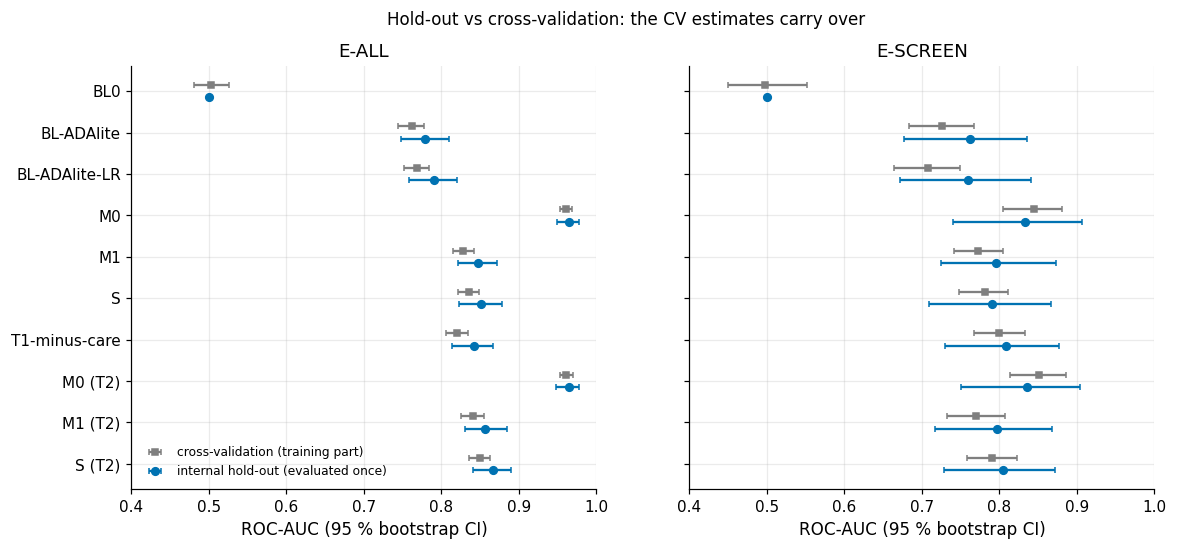

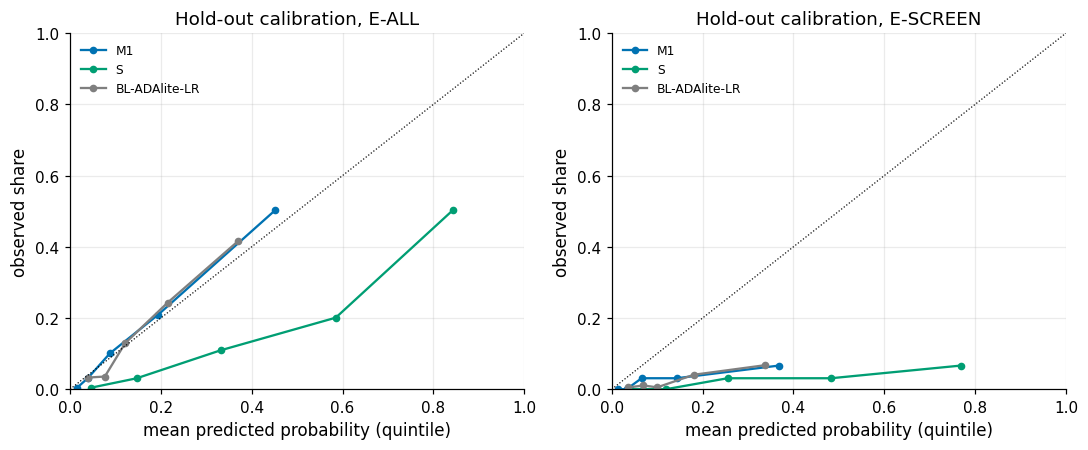

In [28]:
# Figure: hold-out AUC (evaluated once) against the pooled out-of-fold AUC for every arm; rows more than 2 SE below
# CV are labelled. Calibration curves follow, but only when the models were refitted in this run.
if RELEASED or STORED:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    lab_ = [f"{a}" + (" (T2)" if t == 2 else "") for a, t in ho.loc[ho["pop"] == "E-ALL", ["arm", "tier"]].itertuples(index=False)]
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        d = ho[ho["pop"] == pop].reset_index(drop=True)
        yy_ = np.arange(len(d))
        ax.errorbar(d["cv_auc"], yy_ - 0.15, xerr=[d["cv_auc"] - d["cv_lo"], d["cv_hi"] - d["cv_auc"]], fmt="s", color=OI["grey"], capsize=2,
                    ms=4, label="cross-validation (training part)")
        ax.errorbar(d["roc_auc"], yy_ + 0.15, xerr=[d["roc_auc"] - d["auc_lo"], d["auc_hi"] - d["roc_auc"]], fmt="o", capsize=2, ms=5,
                    color=OI["blue"], label="internal hold-out (evaluated once)")
        for i, r in d.iterrows():
            if r["flag_2se_below_cv"]:
                ax.text(r["auc_lo"] - 0.01, i + 0.15, "> 2 SE below CV", ha="right", va="center", fontsize=7, color=OI["vermillion"])
        ax.set(title=pop, xlabel="ROC-AUC (95 % bootstrap CI)", xlim=(0.4, 1.0))
    axes[0].set_yticks(range(len(lab_)), lab_)
    axes[0].invert_yaxis()
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle("Hold-out vs cross-validation: the CV estimates carry over" + ("" if RELEASED else " (stored results of the single evaluation run)"), fontsize=11)
    plots.savefig(fig, "S9_holdout_vs_cv", caption="F9-6. ROC-AUC on the 20 % hold-out (blue; models refitted once on the whole training part, evaluated once "
                  "after exp-freeze) against the pooled out-of-fold estimate on the training part (grey), with 95 % bootstrap CIs; E-ALL left, "
                  "E-SCREEN right (about 25 hold-out positives).")
    plt.show()

if RELEASED:   # needs the refitted models' hold-out predictions
    from sklearn.calibration import calibration_curve
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        yy, m = (y_te, np.ones(len(y_te), bool)) if pop == "E-ALL" else (yesc_te, esc_te)
        for (a, t), col in ((("M1", 1), OI["blue"]), (("S", 1), OI["green"]), (("BL-ADAlite-LR", 1), OI["grey"])):
            # Five quantile bins of the predicted probability, so every bin holds people despite the few
            # positives.
            fr, mp = calibration_curve(yy[m], P_TE[(a, t)][m], n_bins=5, strategy="quantile")
            ax.plot(mp, fr, "o-", color=col, ms=4, label=a)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean predicted probability (quintile)", ylabel="observed share", title=f"Hold-out calibration, {pop}")
        ax.legend(fontsize=8)
    fig.tight_layout()
    plots.savefig(fig, "S9_holdout_calibration", caption="Calibration on the hold-out by quintiles of the predicted probability for M1, S (balanced class weights) "
                  "and BL-ADAlite-LR, Tier 1; E-ALL left, E-SCREEN right.")
    plt.show()
elif STORED:
    print("hold-out calibration curves need the refitted models' predictions; they are part of the stored FINAL outputs "
          "(calibration slope and CITL are in the table above)")

In [29]:
# Log the run and write the hold-out tables. A re-execution must reproduce the numbers of the single evaluation run exactly.
if RELEASED:
    now = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
    if STORED:   # a re-execution must reproduce the numbers of the single evaluation run exactly (deterministic reproduction, not a second look)
        old = pd.read_csv(HOLDOUT_CSV).set_index(["arm", "tier", "pop"])["roc_auc"]
        new = ho.set_index(["arm", "tier", "pop"])["roc_auc"]
        assert old.index.sort_values().equals(new.index.sort_values()), "hold-out arms differ from the single evaluation run"
        dmax = float(np.abs(old.reindex(new.index).to_numpy() - new.to_numpy()).max())
        # Deterministic reproduction: the AUCs must equal the logged one-shot values up to floating-point
        # noise; a larger change would mean the frozen configuration moved.
        assert dmax <= 1e-9, f"hold-out AUCs changed after the single evaluation run (max difference {dmax})"
        oldp = pd.read_csv(HOLDOUT_PAIRS).set_index(["comparison", "pop"])["est"]
        newp = hp.set_index(["comparison", "pop"])["est"]
        assert np.allclose(oldp.reindex(newp.index).to_numpy(), newp.to_numpy(), atol=1e-9), "paired hold-out differences changed"
        print(f"re-execution reproduces the {len(new)} hold-out AUCs of the single evaluation run and {len(newp)} paired differences exactly "
              f"(first run {prev['first_run_utc']}; max |AUC difference| {dmax:.1e})")
    # First-run time and commit are kept from the first execution; only the last-run time and the counter
    # change.
    log_ = dict(first_run_utc=prev["first_run_utc"] if prev else now, last_run_utc=now,
                n_executions=(prev["n_executions"] + 1) if prev else 1, sha256_test_seqn=sha_te, n_test=int(len(cl_te)),
                exp_freeze_commit=RB.head_commit("exp-freeze") or (REC or {}).get("tag_commit"), head_at_first_run=prev["head_at_first_run"] if prev else RB.head_commit(),
                arms=[f"{a} T{t}" for a, t in P_TE], threshold_rule="specificity 0.80 on training-part predictions of the refitted model",
                nb_mode_first_run=prev["nb_mode_first_run"] if prev else C.NB_MODE, frozen=FROZEN, gate=gate)
    HOLDOUT_LOG.write_text(json.dumps(log_, indent=2), encoding="utf-8")
    ho.to_csv(HOLDOUT_CSV, index=False)
    hp.to_csv(OUT / "holdout_pairs.csv", index=False)
    print(json.dumps(log_, indent=1))
    S9["holdout"] = dict(status="re-executed in FINAL mode: reproduces the single evaluation run" if STORED else "evaluated (single evaluation run)",
                         log=log_, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
elif STORED:   # never replace the one-shot results by "not evaluated": store them unchanged, labelled
    S9["holdout"] = dict(status=f"stored results of the single evaluation run, not re-executed in this {C.NB_MODE} run ({REASON})",
                         log=prev, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
    print(S9["holdout"]["status"])
else:
    S9["holdout"] = dict(status=f"not evaluated: gate closed ({REASON}) and no stored results of the single evaluation run")
    print(S9["holdout"]["status"])

re-execution reproduces the 20 hold-out AUCs of the single evaluation run and 9 paired differences exactly (first run 2026-10-11T05:35:17+00:00; max |AUC difference| 1.1e-16)
{
 "first_run_utc": "2026-10-11T05:35:17+00:00",
 "last_run_utc": "2026-10-11T18:17:20+00:00",
 "n_executions": 2,
 "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
 "n_test": 1146,
 "exp_freeze_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
 "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
 "arms": [
  "BL0 T1",
  "BL-ADAlite T1",
  "BL-ADAlite-LR T1",
  "M0 T1",
  "M1 T1",
  "S T1",
  "T1-minus-care T1",
  "M0 T2",
  "M1 T2",
  "S T2"
 ],
 "threshold_rule": "specificity 0.80 on training-part predictions of the refitted model",
 "nb_mode_first_run": "FINAL",
 "frozen": {
  "C0": 0.1,
  "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
  "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
 

**So what.** The internal hold-out check (1,146 adults, 194 positives; E-SCREEN 977 adults, 25 positives) changes no
verdict. **No optimism:** no arm × population row is more than 2 SE below CV; on E-ALL every model scores slightly
*higher* (S 0.851 [0.823, 0.878] vs CV 0.836), as does the unfitted ADA-lite score, so the hold-out sample is
slightly easier. **Contrasts:** the leak gate M1 − M0 replicates on E-ALL (−0.117, supported); S − M1 is +0.004
[−0.007, +0.014] on E-ALL and −0.005 on E-SCREEN (inconclusive, as in CV); the recognition gap of S has the same
direction and size (+0.060 vs +0.055) but is not separately testable with 25 screening positives; S − ADA-lite is
+0.029 [−0.037, +0.098] – **the CV margin does not replicate**. **Calibration:** S over-predicts by design (CITL −1.72).
Nothing was re-tuned. The check is internal: re-running the §4 diagnostics without the hold-out rows changes no design
decision (§9.12), but the hold-out is not an independent sample.

## 12 Post-audit corrections (post-lock)
**Why.** After the lock, an external methodological review raised six issues: (1) the hold-out was not fully
independent of the design, (2) C0 was not nested, (3) Monte Carlo ratio intervals decided two sub-claims, (4) the
reweighing arm used unweighted counts, (5) the M1 coefficient bootstrap did not converge, and (6) M1 keeps the blanket
sentinel recode. Each is checked here as an **approximate post-lock analysis** (`src/postaudit.py`, small resampling
sizes, printed below). No locked verdict, primary arm, stored §3–§8 result or hold-out row is changed;
`governance/hypotheses.md` stays byte-identical. Corrections go into the register (DR-S9-16 to DR-S9-21) and §10.

In [30]:
# Run the six post-audit checks (training part only; the hold-out is only counted in check 1) and display their
# tables. Reads the stored §4/§7/§8 results and the stored folds; writes nothing yet.
from src import postaudit as PA
t_pa = time.time()
PA_SZ = PA.sizes()
print(f"post-audit sizes ({C.NB_MODE}, approximate): nested C on {PA_SZ['nested_folds']} outer folds (repeat 0); "
      f"outer bootstrap {PA_SZ['outer']} x inner B {PA_SZ['inner']}; converged-M1 coefficient bootstrap B = {PA_SZ['coef_b']}")
PA1 = PA.holdout_design_check(ctx)
print("\n(1) hold-out rows inside the full-cohort §4 samples:")
show(PA1["overlap"], 3)
print("§4.11 linearity tests: full cohort (stored) vs training part only")
show(PA1["linearity"], 4)
print(f"interactions: {PA1['interactions_same_class']}/{PA1['interactions_n']} classifications unchanged {PA1['interactions_changed']}; "
      f"VIF > 10 class unchanged {PA1['vif_same_class']}/{PA1['vif_n']} (weight, BMI on training part: "
      f"{PA1['vif_weight_bmi_train'][0]:.1f}, {PA1['vif_weight_bmi_train'][1]:.1f}); max |skew change| {PA1['max_abs_skew_change']:.3f}")
PA2 = PA.nested_c(ctx)
print(f"\n(2) nested C ({PA2['folds_used']}); chosen C per fold: {PA2['cstar']}")
show(PA2["table"], 4)
PA3 = PA.ratio_outer_bootstrap(ctx)
print(f"\n(3) outer patient bootstrap of the BMI SD ratios ({PA3['n_outer']} outer x {PA3['n_inner']} inner refits; approximate)")
show(PA3["table"], 3)
PA4 = PA.weighted_reweighing(ctx)
print("\n(4) reweighing: weighted positive rate (%) by race, training rows of fold 0, and the spread across all folds")
display(PA4["rates_fold0"].query("attribute == 'race'").pivot(index="group", columns="weighting", values="pos_rate_pct").round(2))
show(PA4["spread"], 2)
show(PA4["eod"][["attribute", "group", "eod_S", "eod_asrun", "eod_corrected", "d_eod_corrected", "d_eod_corrected_lo", "d_eod_corrected_hi"]], 3)
show(PA4["auc"], 4)
PA5 = PA.converged_m1_coefs(ctx)
print(f"\n(5) M1 coefficient bootstrap on the first {PA5['n_boot']} resamples of §7.11 (stored §7.11 M1: BMI SD "
      f"{PA5['stored_7_11']['bmi_sd_per_sd']:.3f} over B = {PA5['stored_7_11']['n_boot']}); every refit's solver iterations counted")
show(PA5["table"], 3)
PA6 = PA.m1c_arm(ctx)
print(f"\n(6) M1c = M1 + P02 (codebook sentinel recode; {PA6['label_flips_train']} training labels differ from M1's blanket-recode label)")
show(PA6["table"], 4)
PA_SECONDS = time.time() - t_pa
print(f"post-audit checks: {PA_SECONDS:.0f} s")

post-audit sizes (FINAL, approximate): nested C on 5 outer folds (repeat 0); outer bootstrap 30 x inner B 100; converged-M1 coefficient bootstrap B = 200



(1) hold-out rows inside the full-cohort §4 samples:


sample,n,n_holdout,holdout_pos,holdout_share
"cohort (labels, binned age)",5730,1146,194,0.200
"§4.11 linearity / §4.12 interactions A, C (complete cases, 7 predictors)",4478,901,155,0.201
§4.12 interaction spec B (BMI present),5649,1127,191,0.200


§4.11 linearity tests: full cohort (stored) vs training part only


variable,chi2_full,p_full,chi2_train,p_train,nonlinear_full,nonlinear_train,same_class,splined_P13
RIDAGEYR,57.6075,0.0000,39.8503,0.0000,True,True,True,True
BMXBMI,11.5618,0.0031,9.1497,0.0103,True,True,True,True
BMXWAIST,7.0540,0.0294,7.3327,0.0256,True,True,True,False
bp_sys_mean,5.8698,0.0531,2.2312,0.3277,False,False,True,False
LBDHDD,18.4670,0.0001,15.9249,0.0003,True,True,True,True
LBXTC,41.7673,0.0000,34.4584,0.0000,True,True,True,True
INDFMPIR,0.8344,0.6589,1.1285,0.5688,False,False,True,False


...


(5) M1 coefficient bootstrap on the first 200 resamples of §7.11 (stored §7.11 M1: BMI SD 0.301 over B = 500); every refit's solver iterations counted


variant,bmi_coef_per_sd,bmi_sd_per_sd,q_low,q_high,sign_flip,max_flip_anthro,n_boot,at_limit,ratio_to_S_linear
"M1 stored (lbfgs, max_iter 5,000)",0.585,0.288,-0.176,0.948,0.095,0.840,200,200/200,1.896
M1 exact optimum (newton-cholesky),0.816,0.336,0.221,1.467,0.000,0.130,200,0/200,2.213
M1 + scaling only (P09),0.412,0.115,0.178,0.639,0.000,0.380,200,0/200,0.758



(6) M1c = M1 + P02 (codebook sentinel recode; 5 training labels differ from M1's blanket-recode label)


comparison,pop,auc_a,auc_b,est,lo,hi,interval,mdd,h2b_rule
S - M1,E-ALL,0.8359,0.8285,0.0079,0.0000,0.0158,corrected_t,0.0112,inconclusive
S - M1,E-SCREEN,0.7807,0.7723,0.0085,-0.0076,0.0245,bootstrap,0.0229,inconclusive
S - M1c,E-ALL,0.8359,0.8296,0.0068,-0.0008,0.0144,corrected_t,0.0108,inconclusive
S - M1c,E-SCREEN,0.7807,0.7766,0.0042,-0.0109,0.0189,bootstrap,0.0212,inconclusive
M1c - M1,E-ALL,0.8296,0.8285,0.0011,-0.0019,0.0041,corrected_t,0.0043,supported
M1c - M1,E-SCREEN,0.7766,0.7723,0.0043,0.0002,0.0086,bootstrap,0.0060,supported


post-audit checks: 198 s


In [31]:
# One summary table (issue -> check -> result -> consequence), asserts on the key numbers, storage under
# metrics_S9.json["postaudit"] and results/S9/postaudit_*.csv, and register rows DR-S9-16 to DR-S9-21.
r3b, r3h = PA3["ratio_B3"], PA3["ratio_H2b_c_converged"]
m1c_e, m1c_s = PA6["S_minus_M1c_eall"], PA6["S_minus_M1c_escreen"]
nb, nbs = PA2["dauc_nested"], PA2["dauc_stored"]
_conv_st = PA5["convergence"]["M1 stored (lbfgs, max_iter 5,000)"]
PA_SUM = pd.DataFrame([
    dict(issue="1 hold-out not independent of the design",
         check="§4 linearity, interaction, VIF and skew diagnostics re-run on the training part only",
         result=f"{PA1['lin_sample_holdout']} hold-out rows ({PA1['lin_sample_holdout_pos']} positives) were in the §4.11 sample; on the training part "
                f"{PA1['nl_same_class']}/{PA1['nl_n']} non-linearity and {PA1['interactions_same_class']}/{PA1['interactions_n']} interaction classifications are unchanged; "
                f"the splined set is unchanged",
         consequence="no design decision changes; §9.11 renamed 'internal hold-out check'; limitation L16"),
    dict(issue="2 C0 not nested",
         check=f"C chosen inside each of {PA2['n_folds']} outer folds (repeat 0), same grid",
         result=f"nested C = C0 in {PA2['S_folds_C0']}/{PA2['n_folds']} folds (S) and {PA2['M1_folds_C0']}/{PA2['n_folds']} (M1); S AUC {PA2['S_auc_nested']:.4f} vs "
                f"{PA2['S_auc_stored']:.4f}; ΔAUC S − M1 {nb['est']:+.4f} [{nb['lo']:+.4f}, {nb['hi']:+.4f}] vs {nbs['est']:+.4f} with C0",
         consequence="no change; DR-S9-06 reworded (arm fairness, not nesting); limitation L17"),
    dict(issue="3 Monte Carlo interval decided B3-b and H2b(c)",
         check=f"outer patient bootstrap ({PA3['n_outer']} x {PA3['n_inner']}, approximate)",
         result=f"B3 ratio {r3b['point']:.2f}: Monte Carlo [{r3b['mc_lo']:.2f}, {r3b['mc_hi']:.2f}] vs sampling about [{r3b['outer_q025']:.2f}, {r3b['outer_q975']:.2f}]; "
                f"H2b(c) (converged M1) about [{r3h['outer_q025']:.2f}, {r3h['outer_q975']:.2f}]",
         consequence="B3-b and H2b(c) verdicts withdrawn: not testable with this design; ratios descriptive; B3 mixed and H2b inconclusive unchanged"),
    dict(issue="4 reweighing used unweighted counts",
         check="Kamiran–Calders weights from WTPH2YR-weighted counts, refitted on the stored folds",
         result=f"race positive-rate spread {PA4['race_spread_pp']['survey']:.1f} pp (survey only) -> {PA4['race_spread_pp']['as_fitted']:.1f} pp (as run) -> 0 (corrected); "
                f"EOD NH Black {PA4['eod_nh_black']['corrected']:+.3f} vs {PA4['eod_nh_black']['asrun']:+.3f}, NH Asian {PA4['eod_nh_asian']['corrected']:+.3f} vs "
                f"{PA4['eod_nh_asian']['asrun']:+.3f}; max |ΔAUC| {PA4['max_abs_dauc_corrected']:.4f}",
         consequence="as-run arm described as partial reweighing; 'not adopted' stands (C21)"),
    dict(issue="5 M1 coefficient bootstrap unconverged",
         check=f"M1 at the exact optimum (newton-cholesky) and M1 + scaling (P09), B = {PA5['n_boot']}",
         result=f"same {PA5['n_boot']} resamples: BMI SD {PA5['sd_converged']:.3f} converged vs {PA5['sd_stored']:.3f} as fitted (ratio {PA5['ratio_converged']:.2f} vs {PA5['ratio_stored']:.2f}); "
                f"scaling only {PA5['ratio_scaled']:.2f}; stored refits at the limit {_conv_st['at_limit']}/{_conv_st['n_checked']}",
         consequence="early stopping shrinks the SD (L13 sign corrected); the stability edge of S comes from scaling"),
    dict(issue="6 M1 keeps the blanket recode",
         check="M1c = M1 + P02 on the stored folds, §7 engine",
         result=f"S − M1c E-ALL {m1c_e['est']:+.4f} [{m1c_e['lo']:+.4f}, {m1c_e['hi']:+.4f}]; E-SCREEN {m1c_s['est']:+.4f} [{m1c_s['lo']:+.4f}, {m1c_s['hi']:+.4f}]",
         consequence=f"H2b(a) reading unchanged ({m1c_e['verdict']}); M1 described as naive-minimal"),
])
show(PA_SUM)

# --- asserts on the key numbers (deterministic counts in both modes; resampling-dependent checks in FINAL)
assert PA1["lin_sample_holdout"] == 901 and PA1["lin_sample_holdout_pos"] == 155 and PA1["n_holdout"] == len(ctx.test_idx)
assert PA1["splined_still_nonlinear"] and not PA1["decision_changed"], "a design decision changes on the training part"
assert all(v is None or v < 1e-5 for v in PA2["max_dev_when_C0"].values()), "nested refits with C = C0 must reproduce the stored predictions"
assert abs(PA2["S_auc_change"]) < 0.002, PA2["S_auc_change"]
assert (r3b["outer_q975"] - r3b["outer_q025"]) > (r3b["mc_hi"] - r3b["mc_lo"]), "sampling interval must be wider than the Monte Carlo interval"
assert PA4["race_spread_pp"]["corrected"] < 1e-6, "weighted-count reweighing must make group and label independent"
assert PA4["max_abs_dauc_corrected"] < C.SESOI["roc_auc"]
assert PA5["full_coef_reproduced"] and PA5["convergence"]["M1 exact optimum (newton-cholesky)"]["at_limit"] == 0
assert PA6["label_flips_train"] == 5
if C.IS_FINAL:
    assert PA4["max_dev_asrun_vs_stored"] < 1e-4, "the as-run reweighing arm must reproduce §8.8"
    assert PA5["sd_converged"] > PA5["sd_stored"] and PA5["ratio_scaled"] < 1, "direction of the early-stopping bias"
    assert PA5["share_at_limit_stored"] >= 0.9
    assert m1c_e["verdict"] == "inconclusive" and nb["verdict"] == "inconclusive"

# --- storage
for nm, df in {"postaudit_summary": PA_SUM, "postaudit_holdout_overlap": PA1["overlap"], "postaudit_linearity_train": PA1["linearity"],
               "postaudit_interactions_train": PA1["interactions"], "postaudit_vif_train": PA1["vif"], "postaudit_nested_c": PA2["table"],
               "postaudit_ratio_outer": PA3["table"], "postaudit_ratio_outer_reps": PA3["per_outer"],
               "postaudit_reweighing_rates": PA4["rates_fold0"], "postaudit_reweighing_spread": PA4["spread"],
               "postaudit_reweighing_eod": PA4["eod"], "postaudit_reweighing_auc": PA4["auc"],
               "postaudit_m1_coef": PA5["table"], "postaudit_m1c": PA6["table"]}.items():
    df.to_csv(OUT / f"{nm}.csv", index=False)
_drop = lambda d, ks: {k: v for k, v in d.items() if k not in ks}
S9["postaudit"] = PA.jsonable(dict(
    note="POST-LOCK post-audit checks (approximate, small resampling sizes); locked verdicts, primary arms and the hold-out unchanged",
    sizes=PA_SZ, runtime_seconds=PA_SECONDS,
    holdout_design=_drop(PA1, ("overlap", "skew")),
    nested_c=PA2, ratio_outer=_drop(PA3, ("per_outer",)),
    reweighing=_drop(PA4, ("rates_fold0",)),
    m1_coef=PA5, m1c=PA6, summary=PA_SUM))

# --- decision-register rows (appended after DR-S9-15 in §9.13)
def _reg_pa(i, typ, fnd, ref, val, dec, alt, hyp, loop):
    # The register is append-only: each post-audit row names the earlier rows it supersedes or qualifies.
    return dict(dr_id=f"DR-S9-{i}", stage="S9", date=today, type=typ, finding=fnd, evidence_ref=ref, evidence_value=val, decision=f"{dec}. {loop}",
                alternatives_rejected=alt, hyp_id=hyp, status="decided", check_verdict="PASS",
                check_note="post-audit, post-lock; approximate check (§9.12)", loop_ref=loop, change_request="", commit="")

REG_PA = pd.DataFrame([
    _reg_pa(16, "postaudit_holdout", "Hold-out rows took part in the full-cohort §4/§5 design diagnostics (before the split existed)",
            "results/S9/postaudit_holdout_overlap.csv; postaudit_linearity_train.csv; postaudit_interactions_train.csv; postaudit_vif_train.csv",
            PA_SUM.loc[0, "result"], "Call §9.11 an internal hold-out check, not an independent validation; keep its numbers; add limitation L16",
            "re-splitting or re-scoring the hold-out", "H2a;H2b;H2c",
            "Qualifies DR-S6-12 and DR-S7-01 (the §4/§5 design statistics used the full cohort before the split) and the 'independent check' wording of the original §9.11 / DR-S9-15"),
    _reg_pa(17, "postaudit_tuning", "C0 was chosen once on the whole training part, not nested in the outer folds",
            "results/S9/postaudit_nested_c.csv", PA_SUM.loc[1, "result"],
            "Keep C0 and the 'same model for every arm' rule; report the nested check; add limitation L17",
            "re-running §7 with per-fold tuning (breaks the freeze)", "H2b",
            "Supersedes DR-S7-04 (tuning optimism now bounded by a nested check) and the earlier 'nil optimism' wording of DR-S9-06 (corrected in place: arm fairness, not nesting)"),
    _reg_pa(18, "postaudit_interval", "The §7.11 SD-ratio interval re-draws stored bootstrap replicates: Monte Carlo error, not sampling uncertainty",
            "results/S9/postaudit_ratio_outer.csv; results/S7/coef_stability.csv", PA_SUM.loc[2, "result"],
            "Withdraw the B3-b and H2b(c) verdicts as 'not testable with this design (post-audit)'; keep the ratios as descriptive; "
            "hypotheses.md unchanged; B3 and H2b hypothesis-level verdicts unchanged",
            "keeping the locked-rule verdicts; editing the locked file", "B3;H2b",
            "Supersedes DR-S7-11 (B3-b 'refuted' withdrawn: Monte Carlo interval) and the H2b(c) sub-verdict of the §7 scoreboard; the stored locked labels are kept for traceability"),
    _reg_pa(19, "postaudit_fairness", "§8.8 reweighing used unweighted-count weights multiplied by survey weights: group and label only partly independent",
            "results/S9/postaudit_reweighing_eod.csv; postaudit_reweighing_auc.csv; postaudit_reweighing_spread.csv", PA_SUM.loc[3, "result"],
            "Describe the §8.8 arm as partial reweighing; the corrected weighted-count arm gives the same picture; 'not adopted' stands",
            "replacing the stored §8 arm", "",
            "Qualifies DR-S8-07 and DR-S8-08 (arm as run is partial reweighing; corrected arm agrees, decision unchanged)"),
    _reg_pa(20, "postaudit_stability", "The M1 coefficient bootstrap stops at the iteration limit; early stopping shrinks the BMI SD",
            "results/S9/postaudit_m1_coef.csv", PA_SUM.loc[4, "result"],
            "Correct the sign of L13 and of the §7 'optimiser noise' wording; attribute the stability edge of S to scaling (P09); locked M1 kept",
            "replacing M1 after the lock", "H2b",
            "Supersedes DR-S7-14 ('optimiser noise' wording: early stopping shrinks, not inflates, the M1 BMI SD); complements DR-S7-16"),
    _reg_pa(21, "postaudit_baseline", "M1 keeps the blanket 7/9 sentinel recode (P02 off) in its features and training label",
            "results/S9/postaudit_m1c.csv", PA_SUM.loc[5, "result"],
            "Keep M1 as the locked naive-minimal baseline; report S − M1c as a post-lock comparison", "redefining the primary baseline", "H2b",
            "Qualifies DR-S6-01 and DR-S6-02 (M1 is naive-minimal: blanket sentinel recode; H2b(a) reading unchanged with M1c)"),
])
print(f"stored metrics_S9.json['postaudit'] and {len(REG_PA)} register rows (DR-S9-16 to DR-S9-21); post-audit runtime {PA_SECONDS:.0f} s")

issue,check,result,consequence
1 hold-out not independent of the design,"§4 linearity, interaction, VIF and skew diagnostics re-run on the training part only",901 hold-out rows (155 positives) were in the §4.11 sample; on the training part 7/7 non-linearity and 11/12 interaction classifications are unchanged; the splined set is unchanged,no design decision changes; §9.11 renamed 'internal hold-out check'; limitation L16
2 C0 not nested,"C chosen inside each of 5 outer folds (repeat 0), same grid","nested C = C0 in 5/5 folds (S) and 5/5 (M1); S AUC 0.8333 vs 0.8333; ΔAUC S − M1 +0.0063 [-0.0003, +0.0129] vs +0.0063 with C0","no change; DR-S9-06 reworded (arm fairness, not nesting); limitation L17"
3 Monte Carlo interval decided B3-b and H2b(c),"outer patient bootstrap (30 x 100, approximate)","B3 ratio 1.36: Monte Carlo [1.23, 1.50] vs sampling about [0.99, 2.05]; H2b(c) (converged M1) about [1.87, 2.76]",B3-b and H2b(c) verdicts withdrawn: not testable with this design; ratios descriptive; B3 mixed and H2b inconclusive unchanged
4 reweighing used unweighted counts,"Kamiran–Calders weights from WTPH2YR-weighted counts, refitted on the stored folds","race positive-rate spread 11.1 pp (survey only) -> 4.0 pp (as run) -> 0 (corrected); EOD NH Black -0.133 vs -0.131, NH Asian -0.189 vs -0.201; max |ΔAUC| 0.0053",as-run arm described as partial reweighing; 'not adopted' stands (C21)
5 M1 coefficient bootstrap unconverged,"M1 at the exact optimum (newton-cholesky) and M1 + scaling (P09), B = 200",same 200 resamples: BMI SD 0.336 converged vs 0.288 as fitted (ratio 2.21 vs 1.90); scaling only 0.76; stored refits at the limit 200/200,early stopping shrinks the SD (L13 sign corrected); the stability edge of S comes from scaling
6 M1 keeps the blanket recode,"M1c = M1 + P02 on the stored folds, §7 engine","S − M1c E-ALL +0.0068 [-0.0008, +0.0144]; E-SCREEN +0.0042 [-0.0109, +0.0189]",H2b(a) reading unchanged (inconclusive); M1 described as naive-minimal


stored metrics_S9.json['postaudit'] and 6 register rows (DR-S9-16 to DR-S9-21); post-audit runtime 198 s


**So what.** No issue changes a locked verdict or a headline number, but three change how results are read. The hold-out
is an *internal* check: 901 of its rows (155 positives) entered the §4 non-linearity tests, yet the training part alone
gives the same design (7/7 non-linearity, 11/12 interaction classifications). Nesting C changes nothing (C0 chosen
in 5/5 folds). The B3-b and H2b(c) verdicts are withdrawn: the approximate sampling interval of the B3 ratio (about
1.0–2.1) is far wider than its Monte Carlo interval (1.23–1.50). Weighted-count reweighing and M1 with the codebook
recode (S − M1c +0.007 [−0.001, +0.014]) leave the conclusions unchanged. Early stopping *shrinks* M1's BMI SD (0.288
against 0.336 converged); the stability edge of S is scaling (scaled-M1 ratio 0.76).

## 13 Outputs
**Why.** §10 and the video read every number from stored artefacts: `results/metrics_S9.json`, the tables in
`results/S9/`, the F9 figures and the §9 decision-register fragment (written from the FINAL run, listed below).

In [32]:
# Add the hold-out row to the decision register (only if the hold-out was evaluated or reproduced in this
# run), list the register, write it in FINAL mode and save results/metrics_S9.json.
if RELEASED and "metrics" in S9["holdout"]:
    hS = ho[(ho["arm"] == "S") & (ho["tier"] == 1)].set_index("pop")
    hpS = hp.set_index(["comparison", "pop"])
    reg = pd.concat([reg, pd.DataFrame([dict(
        dr_id="DR-S9-15", stage="S9", date=today, type="holdout",
        finding="Internal hold-out check, evaluated once after exp-freeze (design-informed through the full-cohort §4/§5 diagnostics, L16)",
        evidence_ref="results/S9/holdout_metrics.csv; results/S9/holdout_pairs.csv; results/S9/holdout_log.json; figures/S9_holdout_vs_cv.png",
        evidence_value=(f"S T1 AUC E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}] (CV {hS.loc['E-ALL', 'cv_auc']:.3f}), "
                        f"E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} [{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}] (CV {hS.loc['E-SCREEN', 'cv_auc']:.3f}); "
                        f"S - M1 E-ALL {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'est']:+.4f} [{hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'lo']:+.4f}, {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'hi']:+.4f}]; "
                        f"{int(ho['flag_2se_below_cv'].sum())} of {len(ho)} arm x population rows > 2 SE below CV; SHA-256 {sha_te[:16]}"),
        decision="Report hold-out numbers as they are; no re-tuning", alternatives_rejected="re-tuning after seeing the hold-out",
        hyp_id="H2a;H2b;H2c", status="decided", check_verdict="PASS", check_note=f"first run {S9['holdout']['log']['first_run_utc']}",
        loop_ref="", change_request="", commit="")])], ignore_index=True)
# Post-audit rows (§9.12) follow the hold-out row.
reg = pd.concat([reg, REG_PA[reg.columns]], ignore_index=True)
show(reg[["dr_id", "type", "check_verdict", "decision"]])
if C.IS_FINAL:
    # The register is append-only: a row already on file keeps its original date unless its content changed.
    if REG_PATH.exists():
        old_reg = pd.read_csv(REG_PATH, dtype=str, keep_default_na=False).set_index("dr_id")
        for i, r in reg.iterrows():
            if r["dr_id"] in old_reg.index and all(str(r[c]) == old_reg.loc[r["dr_id"], c] for c in reg.columns
                                                   if c not in ("dr_id", "date") and c in old_reg.columns):
                reg.at[i, "date"] = old_reg.loc[r["dr_id"], "date"]
    # Only a FINAL run writes the register fragment; a FAST run must not overwrite the committed one.
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S9["register_ids"] = reg["dr_id"].tolist()
S9["runtime_seconds"] = time.time() - T_START
# Write results/metrics_S9.json (the `S9` dictionary built up in this section).
R.save_section("S9", S9)
print(f"saved results/metrics_S9.json; section runtime {S9['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps({"H2b(a) reference": S9["reference"]["E-ALL"]["h2b"], "seeds stable": S9["seeds"]["stable_eall"],
                  "sensitivity same verdict": f"{S9['sensitivity']['eall_same_verdict']}/{S9['sensitivity']['eall_rows']}",
                  "L3 triggered": S9["leak_hunt"]["triggered"], "hold-out": S9["holdout"]["status"]}, indent=1))

dr_id,type,check_verdict,decision
DR-S9-01,negative_control,PASS,Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt
DR-S9-02,negative_control,PASS,No overfitting to noise; depth cap 3 for the tree probe retained
DR-S9-03,positive_control,PASS,Procedure has power for weak real signals; negative controls are not passed by blindness
DR-S9-04,seed_stability,PASS,H2b(a) verdict graded seed-stable
DR-S9-05,sensitivity,PASS,"H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)"
DR-S9-06,tuning,PASS,"Tuning C on S does not favour S across arms (M0, M1 and S pick the same C); 'same model for every arm' rule kept. This tests arm fairness, not nesting: the tuning optimism of the un-nested C0 is bounded by the post-audit nested check (DR-S9-17)"
DR-S9-07,sensitivity,PASS,Extension item; does not change the core table
DR-S9-08,sensitivity,PASS,Stratified (non-grouped) folds kept as primary design
DR-S9-09,missingness,PASS,Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions
DR-S9-10,validation,PASS,"Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label"


wrote governance/register/S9.csv (21 rows)
saved results/metrics_S9.json; section runtime 1318 s (FINAL)
{
 "H2b(a) reference": "inconclusive",
 "seeds stable": true,
 "sensitivity same verdict": "17/17",
 "L3 triggered": false,
 "hold-out": "re-executed in FINAL mode: reproduces the single evaluation run"
}
